# Lagunazo CRMs volumetric and tonnage assessments

## 1 · Imports & Configuration

In [65]:
import os, re, io, json, time, math, zipfile, hashlib, platform, warnings
import xml.etree.ElementTree as ET
from datetime import datetime, timezone
from pathlib import Path
from IPython.display import display, HTML, Markdown
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scipy
import openpyxl
from scipy.spatial import cKDTree
from scipy import stats
from scipy import sparse
from scipy.sparse.linalg import spsolve
from scipy.optimize import curve_fit

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patheffects as mpe
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D
from matplotlib.path import Path as MPath

try:
    import pyproj
    from pyproj import Transformer
except ImportError:
    raise ImportError("pyproj is required for the WGS 84 -> UTM 29N projection (pip install pyproj).")
try:
    import shapely
    from shapely.geometry import Polygon as ShapelyPolygon, MultiPoint, Point
    SHAPELY_OK = True
except ImportError:
    shapely, SHAPELY_OK = None, False
    print("warning: shapely not found - polygon handling falls back to matplotlib (pip install shapely).")
try:
    pd.DataFrame({"a": [1]}).style.to_html()
    JINJA_OK = True
except Exception:
    JINJA_OK = False

matplotlib.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 9.5, "axes.titlesize": 10.5, "axes.labelsize": 9.5,
    "axes.linewidth": 0.9, "xtick.direction": "in", "ytick.direction": "in",
    "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42, "svg.fonttype": "none"})

# input files
ICP_XLSX   = "ICP-DATA_2026.xlsx"          # laboratory Final Report workbook
SHEET_DATA = "Analytical Data"
SHEET_QC   = "QC Data"
SHEET_LOC  = "Locations"
KMZ_FILE   = "Lagunazo_waste_area.kmz"     # mine-waste boundary polygon
DEM_FILE   = "Lagunazo.dem"                # USGS ASCII DEM of the waste surface (UTM 29N, metres)
OUT_DIR    = "results_pXRF_PbFe_base193"
EPSG_UTM   = "EPSG:32629"

# sample-ID reconciliation (OK r2)
LAB_TO_FIELD_PREFIX = {"LA": "LG"}
LOCATION_ID_FIXES = [
    dict(no=13, recorded="LG-35-31", corrected="LG-25-31", kind="typo",
         reason="year field '35' is a typo; point lies in the LG-25-33 -> 31 -> 29 field sequence"),
    dict(no=23, recorded="LH-25-06", corrected="LG-25-06", kind="typo",
         reason="prefix 'LH' is a typo; point lies in the LG-25-07 -> 06 -> 05 field sequence"),
    dict(no=29, recorded="LG-25-34", corrected="LG-25-24", kind="inferred",
         reason="LG-25-34 is recorded twice (No. 29 and No. 44) and LG-25-24 is otherwise missing; "
                "No. 29 lies between LG-25-25 and LG-25-23 in the field sequence"),
]
APPLY_INFERRED_FIXES = True

# censored assays, eligibility (OK r2)
BDL_FACTOR     = 0.5    # "<MDL" -> BDL_FACTOR x MDL
ODL_FACTOR     = 1.0    # ">UDL" -> the upper limit (a LOWER BOUND - flagged everywhere)
MIN_QUANT_FRAC = 0.15
MIN_QUANT_FRAC_STRICT = 0.70
MIN_DETECTED_N = 5
MIN_N_MAP      = 15
STATION_TOL_M  = 5.0

# Stage B: CRM screening
SHORTLIST_MIN_QUANT_PCT = 70.0   # located samples quantified (above MDL and below the upper limit), per cent
SHORTLIST_MIN_CF        = 5.0    # median concentration factor against the upper continental crust
#   Upper continental crust, Rudnick & Gao (2014, Treatise on Geochemistry 2nd ed., Table 3), in ppm.
#   Ti, Al, Mg, Mn, P converted from the oxides (TiO2 0.64, Al2O3 15.4, MgO 2.48, MnO 0.10, P2O5 0.15 wt %).
UCC_PPM = {"Li": 24, "Be": 2.1, "B": 17, "Mg": 14955, "Al": 81505, "P": 655, "Sc": 14.0, "Ti": 3836, "V": 97,
           "Mn": 774, "Co": 17.3, "Ni": 47, "Cu": 28, "Ga": 17.5, "Ge": 1.4, "As": 4.8, "Sr": 320, "Y": 21,
           "Nb": 12, "Pd": 0.00052, "Sb": 0.4, "Ba": 628, "La": 31, "Ce": 63, "Hf": 5.3, "Ta": 0.9, "W": 1.9,
           "Pt": 0.0005, "Bi": 0.16,
           # not CRMs under Regulation (EU) 2024/1252 - used only for the co-product context table
           "Pb": 17, "Fe": 39180, "Ag": 0.053, "Au": 0.0015, "Zn": 67, "Sn": 2.1, "In": 0.056, "Hg": 0.05, "Se": 0.09}
#   Elements that are listed CRMs but are a processing penalty / environmental liability rather than a product.
DELETERIOUS = {"As": "listed CRM, but in sulphide mine waste arsenic is a penalty element and an environmental "
                     "liability; it is inventoried, not ranked as a recovery target"}
#   World production, tonnes of contained element per year (USGS Mineral Commodity Summaries 2026, 2025 estimates):
#   Sb mine production 110,000 t; Bi refinery production 16,000 t; Cu mine production 23,000,000 t;
#   As2O3 61,000 t gross weight = 46,200 t As (x 0.7574).
WORLD_PRODUCTION_T = {"Sb": 110_000, "Bi": 16_000, "Cu": 23_000_000, "As": 46_200}
#   Break-even cut-off grades in ppm, if available from the cut-off notebook. None = not evaluated.   [CONFIRM]
CUTOFF_PPM = {"Sb": None, "Bi": None, "Cu": None, "As": None, "Fe": None, "Pb": None}
RESOURCE_ELEMENTS = ["Pb", "Fe"]          # None = the Stage-B shortlist | e.g. ["Sb", "Bi", "Cu"]

# Stage C: DEM, base elevation, volume, density
BASE_ELEVATION_M = 193.0          # base of the waste, m a.s.l. (base case). The waste fills the column from the DEM
                                  # surface down to this elevation and is homogeneous through its thickness.
GRID_DENSITY_M   = 3.0            # block size = the kriging lattice of the OK / IDW notebooks
BULK_DENSITY     = dict(low=1.10, base=1.25, high=1.40)   # dry bulk density, t/m3   [CONFIRM: measured value and range]

# Stage D: variogram, models, kriging (OK r2)
TRANSFORM_CANDIDATES   = ["none", "log", "nscore"]
TRANSFORM_MIN_GAIN_PCT = 2.0
LOG_BACKTRANSFORM      = "journel"
NSCORE_BACKTRANSFORM   = "expectation"
NSCORE_UPPER_OMEGA     = 1.5
NSCORE_ZMAX_FACTOR     = 2.0
GH_NODES               = 24
N_BOOT                 = 2000
MARGINAL_P             = 0.25
N_LAGS_MAX     = 15
MIN_PAIRS_LAG  = 30
CUTOFF_FACTOR  = 0.50
RMSSE_PENALTY     = 0.15
SELECTION_TOL_PCT = 2.0
GAUSSIAN_MIN_NUGGET_FRAC = 1e-3
MODEL_PREFERENCE = ["Nugget", "Spherical", "Exponential", "Cubic", "Gaussian"]
K_NEIGHBORS          = 16
MIN_NEIGHBORS        = 6
SEARCH_RADIUS_FACTOR = 1.6
MIN_STATIONS, MIN_PAIRS_TOTAL, MIN_DISTINCT_VALS = 10, 45, 3
MIN_R2_SURFACE = 0.10             # nested-CV R2 needed before the kriged surface is used for the tonnage-grade link
PAD_FRAC       = 0.06

# Stage E: ranges, sensitivity
CI_LEVEL        = 0.90            # confidence level of the grade range
ODL_SENS_FACTOR = 1.5             # sensitivity: over-range (">UDL") assays set to this multiple of the upper limit
ET_SIG_FIGS     = 2               # rounding of the Exploration Target ranges

SAVE_FIGURES = True
FIG_FORMATS  = ("png", "pdf")

for _f in (ICP_XLSX, KMZ_FILE, DEM_FILE):
    if not Path(_f).exists():
        raise FileNotFoundError(f"'{_f}' not found in {Path.cwd()} - place it next to this notebook.")
os.makedirs(OUT_DIR, exist_ok=True)
RUN_STARTED = datetime.now(timezone.utc).isoformat(timespec="seconds")
Z_CI = float(stats.norm.ppf(0.5 + CI_LEVEL / 2))
print("Configuration loaded.")
print(f"  Inputs   : {ICP_XLSX} | {KMZ_FILE} | {DEM_FILE}   ->   {OUT_DIR}/")
print(f"  Base     : {BASE_ELEVATION_M:g} m a.s.l., homogeneous through the thickness   |   bulk density {BULK_DENSITY['low']:g} / {BULK_DENSITY['base']:g} / "
      f"{BULK_DENSITY['high']:g} t/m3 (low / base / high)")
print(f"  Shortlist: >= {SHORTLIST_MIN_QUANT_PCT:g} % quantified and median concentration factor >= {SHORTLIST_MIN_CF:g}")
print(f"  Kriging  : K={K_NEIGHBORS}, min {MIN_NEIGHBORS}, radius = max({SEARCH_RADIUS_FACTOR} x range, 5 x spacing); "
      f"transforms {TRANSFORM_CANDIDATES}")

Configuration loaded.
  Inputs   : ICP-DATA_2026.xlsx | Lagunazo_waste_area.kmz | Lagunazo.dem   ->   results_pXRF_PbFe_base193/
  Base     : 193 m a.s.l., homogeneous through the thickness   |   bulk density 1.1 / 1.25 / 1.4 t/m3 (low / base / high)
  Shortlist: >= 70 % quantified and median concentration factor >= 5
  Kriging  : K=16, min 6, radius = max(1.6 x range, 5 x spacing); transforms ['none', 'log', 'nscore']


## 2 · Core Routines (unchanged from `Final_ICP_OK_Lagunazo_r2.ipynb`)

In [66]:
# tables
_STATUS_CSS = {"PASS": "background-color:#eafaf1;color:#1e8449;font-weight:bold",
               "WARN": "background-color:#fef9e7;color:#b7950b;font-weight:bold",
               "FAIL": "background-color:#fdedec;color:#922b21;font-weight:bold",
               "INFO": "background-color:#eaf2f8;color:#1a5276;font-weight:bold"}

def show_table(df, precision=None, status_col=None):
    """Display a DataFrame without its index; Styler when available, plain HTML otherwise."""
    if JINJA_OK:
        try:
            sty = df.style
            if precision is not None:
                sty = sty.format(precision=precision, thousands=",")
            if status_col is not None:
                colour = sty.map if hasattr(sty, "map") else sty.applymap
                sty = colour(lambda v: _STATUS_CSS.get(v, ""), subset=[status_col])
            display(sty.hide(axis="index"))
            return
        except Exception:
            pass
    d = df.copy()
    if precision is not None:
        num = d.select_dtypes("number").columns
        d[num] = d[num].round(precision)
    html = d.to_html(index=False, na_rep="", escape=True)
    if status_col is not None:
        for key, css in _STATUS_CSS.items():
            html = html.replace(f"<td>{key}</td>", f'<td style="{css}">{key}</td>')
    display(HTML(html))


# stations
def station_means(df, x_col, y_col, var, tol_m=5.0, id_col=None, flag_col=None):
    """Collapse replicates within tol_m (single linkage) to one station; returns (stations, report)."""
    d = df.copy()
    for c in (x_col, y_col, var):
        d[c] = pd.to_numeric(d[c], errors="coerce")
    d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=[x_col, y_col, var]).reset_index(drop=True)
    xy = d[[x_col, y_col]].to_numpy(float)
    parent = np.arange(len(d))

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    for a, b in cKDTree(xy).query_pairs(r=max(tol_m, 1e-9)):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra
    d["_station"] = [find(i) for i in range(len(d))]
    agg = {x_col: (x_col, "mean"), y_col: (y_col, "mean"), var: (var, "mean"),
           "n_reps": (var, "size"), "rep_sd": (var, "std")}
    if id_col:
        agg[id_col] = (id_col, lambda s: "+".join(map(str, s)))
    if flag_col:
        agg[flag_col] = (flag_col, lambda s: ",".join(sorted(set(map(str, s)))))
    out = d.groupby("_station").agg(**agg).reset_index(drop=True)
    rep = dict(n_measurements=int(len(d)), n_stations=int(len(out)),
               n_stations_with_reps=int((out["n_reps"] > 1).sum()),
               median_rep_sd=float(out.loc[out["n_reps"] > 1, "rep_sd"].median())
               if (out["n_reps"] > 1).any() else np.nan)
    return out.drop(columns=["rep_sd"]), rep


# declustering
def declustering_weights(coords, values, cell_sizes=None, n_origins=12, target="min_mean", seed=0):
    """Cell declustering (GSLIB declus): origin-averaged weights (mean 1) at the cell size that minimises
    (or maximises) the declustered mean. Returns (weights, cell_size_m, table)."""
    coords, v = np.asarray(coords, float), np.asarray(values, float)
    n = len(v)
    if n < 3:
        return np.ones(n), np.nan, pd.DataFrame()
    if cell_sizes is None:
        nn = float(np.median(cKDTree(coords).query(coords, k=2)[0][:, 1]))
        ext = float(max(np.ptp(coords[:, 0]), np.ptp(coords[:, 1])))
        cell_sizes = np.unique(np.round(np.linspace(max(nn, 1.0), max(ext / 2.0, nn * 1.01), 24), 1))
    rng = np.random.default_rng(seed)
    x0, y0 = coords[:, 0].min(), coords[:, 1].min()
    rows, W = [], {}
    for cs in cell_sizes:
        acc = np.zeros(n)
        for o in range(n_origins):
            ox, oy = (0.0, 0.0) if o == 0 else (rng.uniform(0, cs), rng.uniform(0, cs))
            ix = np.floor((coords[:, 0] - x0 + ox) / cs).astype(np.int64)
            iy = np.floor((coords[:, 1] - y0 + oy) / cs).astype(np.int64)
            _, inv, cnt = np.unique(np.column_stack([ix, iy]), axis=0, return_inverse=True, return_counts=True)
            w = 1.0 / cnt[np.asarray(inv).ravel()]
            acc += w * n / w.sum()
        w = acc / n_origins
        w *= n / w.sum()
        W[float(cs)] = w
        rows.append((float(cs), float(np.sum(w * v) / n)))
    tab = pd.DataFrame(rows, columns=["cell_size_m", "declustered_mean"])
    i = tab["declustered_mean"].idxmin() if target == "min_mean" else tab["declustered_mean"].idxmax()
    cs = float(tab.loc[i, "cell_size_m"])
    return W[cs], cs, tab


# metrics
def metrics(y_true, y_pred, label=""):
    """Cross-validation statistics in grade units."""
    yt, yp = np.asarray(y_true, float), np.asarray(y_pred, float)
    ok = np.isfinite(yt) & np.isfinite(yp)
    yt, yp = yt[ok], yp[ok]
    if yt.size < 2:
        return {}
    res = yp - yt
    ss_tot = float(np.sum((yt - yt.mean()) ** 2))
    rmse = float(np.sqrt(np.mean(res ** 2)))
    good = np.std(yt) > 0 and np.std(yp) > 0
    return dict(
        Label=label, n=int(yt.size), RMSE=rmse, MAE=float(np.mean(np.abs(res))), ME_bias=float(res.mean()),
        Rel_bias_pct=float(100 * res.mean() / yt.mean()) if yt.mean() else np.nan,
        Rel_RMSE_pct=float(100 * rmse / yt.mean()) if yt.mean() else np.nan,
        R2_pred=float(1 - np.sum(res ** 2) / ss_tot) if ss_tot > 0 else np.nan,
        Pearson_r=float(np.corrcoef(yt, yp)[0, 1]) if good else np.nan,
        Spearman_r=float(stats.spearmanr(yt, yp)[0]),
        Slope_obs_on_pred=float(stats.linregress(yp, yt)[0]) if good else np.nan,   # conditional bias, ideal 1
        Reg_slope=float(stats.linregress(yt, yp)[0]) if good else np.nan,           # smoothing
        Obs_min=float(yt.min()), Obs_max=float(yt.max()), Est_min=float(yp.min()), Est_max=float(yp.max()),
        Var_ratio=float(np.var(yp, ddof=1) / np.var(yt, ddof=1)) if np.var(yt) > 0 else np.nan)

print("Tables, stations, declustering and metrics loaded.")


Tables, stations, declustering and metrics loaded.


In [67]:
# variogram models 
# Practical-range parameterisation (the model reaches ~95 % (exp, gau) or 100 % (sph, cub) of the sill at `rng`).
def _sph(h, a):
    r = np.minimum(h / a, 1.0)
    return 1.5 * r - 0.5 * r ** 3

def _exp(h, a):
    return 1.0 - np.exp(-3.0 * h / a)

def _gau(h, a):
    return 1.0 - np.exp(-3.0 * (h / a) ** 2)

def _cub(h, a):
    r = np.minimum(h / a, 1.0)
    return 7 * r ** 2 - 8.75 * r ** 3 + 3.5 * r ** 5 - 0.75 * r ** 7

SHAPES = {"Spherical": _sph, "Exponential": _exp, "Gaussian": _gau, "Cubic": _cub}


class VModel:
    """Nugget + one structure. gamma(0) = 0 (the nugget is a discontinuity at the origin)."""

    def __init__(self, name, nugget, psill, rng):
        self.name, self.nugget, self.psill, self.rng = name, float(nugget), float(psill), float(rng)

    @property
    def sill(self):
        return self.nugget + self.psill

    def gamma(self, h):
        h = np.asarray(h, float)
        g = np.full(h.shape, self.nugget)
        if self.name != "Nugget":
            g = g + self.psill * SHAPES[self.name](h, self.rng)
        return np.where(h <= 1e-9, 0.0, g)

    def rho(self, h):
        """Covariance normalised by the sill: 1 at h = 0."""
        return 1.0 - self.gamma(h) / self.sill

    def __repr__(self):
        return (f"{self.name}(nugget={self.nugget:.4g}, psill={self.psill:.4g}, "
                + ("" if self.name == "Nugget" else f"range={self.rng:.1f} m, ") + f"N:S={self.nugget / self.sill:.2f})")


def experimental_variogram(coords, y, cutoff, min_pairs=MIN_PAIRS_LAG, n_lags_max=N_LAGS_MAX):
    """Omnidirectional semivariogram with EQUAL-COUNT lags: every lag holds >= min_pairs pairs by construction.
    Returns DataFrame(lag, h_mean, h_min, h_max, gamma, n_pairs)."""
    coords, y = np.asarray(coords, float), np.asarray(y, float)
    iu = np.triu_indices(len(y), k=1)
    h = np.hypot(coords[iu[0], 0] - coords[iu[1], 0], coords[iu[0], 1] - coords[iu[1], 1])
    g = 0.5 * (y[iu[0]] - y[iu[1]]) ** 2
    keep = (h > 0) & (h <= cutoff)
    h, g = h[keep], g[keep]
    n_lags = int(min(n_lags_max, h.size // max(min_pairs, 1)))
    if n_lags < 1:
        return pd.DataFrame(columns=["lag", "h_mean", "h_min", "h_max", "gamma", "n_pairs"])
    order = np.argsort(h, kind="mergesort")
    rows = []
    for i, s in enumerate(np.array_split(order, n_lags)):
        rows.append((i + 1, h[s].mean(), h[s].min(), h[s].max(), g[s].mean(), s.size))
    return pd.DataFrame(rows, columns=["lag", "h_mean", "h_min", "h_max", "gamma", "n_pairs"])


def fit_models(vgm, cutoff):
    """Weighted least squares (weights = pair counts; with equal-count lags these are near-equal, so the fit is
    effectively unweighted) for four structured models + the pure-nugget benchmark.
    Parameterised as nugget + PARTIAL sill so both are >= 0. Returns list of (VModel, bound_hits, wrss)."""
    xf, yf, wf = (vgm[c].to_numpy(float) for c in ("h_mean", "gamma", "n_pairs"))
    gmax = float(yf.max())
    nug_hi, ps_hi = max(1.05 * gmax, 1e-12), max(1.5 * gmax, 1e-12)
    r_lo = float(max(0.5 * xf.min(), 1.0))
    r_hi = float(max(1.5 * cutoff, 4 * r_lo))
    nug0 = float(np.clip(min(yf[0], np.percentile(yf, 25)), 0.0, nug_hi))
    ps0 = float(np.clip(max(np.median(yf[-3:]) - nug0, 0.05 * gmax), 0.0, ps_hi))
    rg0 = float(np.clip(0.4 * xf.max(), r_lo, r_hi))
    sigma = 1.0 / np.sqrt(np.maximum(wf, 1e-9))
    out = []
    for name, shape in SHAPES.items():
        lo, hi = [0.0, 0.0, r_lo], [nug_hi, ps_hi, r_hi]
        if name == "Gaussian":
            lo[0] = GAUSSIAN_MIN_NUGGET_FRAC * gmax          # a zero-nugget Gaussian is numerically singular
        p0 = [float(np.clip(v, l_, h_)) for v, l_, h_ in zip([nug0, ps0, rg0], lo, hi)]
        try:
            popt, _ = curve_fit(lambda h, c0, c, a: c0 + c * shape(h, a), xf, yf, p0=p0, sigma=sigma,
                                bounds=(lo, hi), maxfev=200000)
        except (RuntimeError, ValueError):
            continue
        hits = [nm for nm, v, l_, h_ in zip(("nugget", "psill", "range"), popt, lo, hi)
                if (h_ - l_) > 0 and (abs(v - l_) <= 1e-2 * (h_ - l_) or abs(h_ - v) <= 1e-2 * (h_ - l_))
                and not (nm == "nugget" and v <= lo[0] + 1e-12 and name != "Gaussian")]
        m = VModel(name, *popt)
        out.append((m, hits, float(np.sum(wf * (m.gamma(xf) - yf) ** 2))))
    c0 = float(np.average(yf, weights=wf))
    m = VModel("Nugget", c0, 0.0, cutoff)
    out.append((m, [], float(np.sum(wf * (c0 - yf) ** 2))))
    return out

print("Variogram models and fitting loaded.")


Variogram models and fitting loaded.


In [68]:
# ordinary kriging engine 
def _select_neighbours(d, ix, K, min_k, radius):
    """d, ix sorted by distance. Use the neighbours inside `radius` (at most K); if fewer than min_k are inside,
    use the min_k nearest (extended). The used set is always a prefix of the sorted list."""
    within = d <= radius
    n_in = within.sum(axis=1)
    m = np.where(n_in >= min_k, np.minimum(n_in, K), np.minimum(min_k, d.shape[1]))
    return m.astype(int), n_in < min_k


def ok_batch(targets, coords, y, model, K=K_NEIGHBORS, min_k=MIN_NEIGHBORS, radius=np.inf,
             exclude_self=False, chunk=4000):
    """Batched ordinary kriging at `targets`. With exclude_self=True the targets are the stations themselves
    and each is kriged from the others (leave-one-out).
    Returns dict(est, var, mu, n_used, extended, cond_max)."""
    coords, y = np.asarray(coords, float), np.asarray(y, float)
    targets = np.atleast_2d(np.asarray(targets, float))
    n, T = len(y), len(targets)
    Kq = int(min(K if K else n, n - (1 if exclude_self else 0)))
    kq = Kq + (1 if exclude_self else 0)
    d, ix = cKDTree(coords).query(targets, k=kq)
    d, ix = np.asarray(d).reshape(T, kq), np.asarray(ix).reshape(T, kq)
    if exclude_self:
        selfc = ix == np.arange(T)[:, None]
        selfc[~selfc.any(axis=1), -1] = True
        d, ix = d[~selfc].reshape(T, Kq), ix[~selfc].reshape(T, Kq)
    m_used, extended = _select_neighbours(d, ix, Kq, min(min_k, Kq), radius)
    est, var, mu = np.full(T, np.nan), np.full(T, np.nan), np.full(T, np.nan)
    cond_max = 0.0
    for m in np.unique(m_used):
        rows = np.flatnonzero(m_used == m)
        for s in range(0, rows.size, chunk):
            R = rows[s:s + chunk]
            I = ix[R, :m]
            P = coords[I]                                               # (g, m, 2)
            D = np.hypot(P[:, :, None, 0] - P[:, None, :, 0], P[:, :, None, 1] - P[:, None, :, 1])
            A = np.zeros((R.size, m + 1, m + 1))
            A[:, :m, :m] = model.rho(D)
            A[:, :m, m] = 1.0
            A[:, m, :m] = 1.0
            b = np.ones((R.size, m + 1))
            b[:, :m] = model.rho(d[R, :m])
            try:
                sol = np.linalg.solve(A, b[..., None])[..., 0]
            except np.linalg.LinAlgError:
                sol = np.stack([np.linalg.lstsq(A[j], b[j], rcond=None)[0] for j in range(R.size)])
            lam, nu = sol[:, :m], sol[:, m]
            est[R] = np.sum(lam * y[I], axis=1)
            var[R] = model.sill * np.maximum(1.0 - np.sum(lam * b[:, :m], axis=1) - nu, 0.0)
            mu[R] = -model.sill * nu                                    # semivariogram-form multiplier
            if R.size <= 64 or s == 0:
                cond_max = max(cond_max, float(np.max(np.linalg.cond(A[:64]))))
    return dict(est=est, var=var, mu=mu, n_used=m_used, extended=extended, cond_max=cond_max)


def ok_point_gamma(pt, coords, y, model, K=K_NEIGHBORS, min_k=MIN_NEIGHBORS, radius=np.inf):
    """Independent reference solver for ONE target in the SEMIVARIOGRAM form
    [Gamma 1; 1' 0][lambda; mu] = [gamma0; 1], sigma2 = lambda.gamma0 + mu. Used only in the audit."""
    dd = np.hypot(coords[:, 0] - pt[0], coords[:, 1] - pt[1])
    order = np.argsort(dd, kind="mergesort")[:min(K if K else len(y), len(y))]
    inside = order[dd[order] <= radius]
    use = inside[:K] if inside.size >= min_k else order[:min_k]
    P = coords[use]
    G = model.gamma(np.hypot(P[:, None, 0] - P[None, :, 0], P[:, None, 1] - P[None, :, 1]))
    m = len(use)
    A = np.zeros((m + 1, m + 1)); A[:m, :m] = G; A[:m, m] = 1; A[m, :m] = 1
    g0 = model.gamma(dd[use])
    sol = np.linalg.solve(A, np.append(g0, 1.0))
    lam, mu_g = sol[:m], sol[m]
    return float(lam @ y[use]), float(lam @ g0 + mu_g), float(mu_g), lam, use


def search_radius_for(model, spacing):
    return float(max(model.rng * SEARCH_RADIUS_FACTOR, 5.0 * spacing))

print("Ordinary kriging engine loaded.")


Ordinary kriging engine loaded.


In [69]:
# transforms
class Transform:
    """none | log | nscore with explicit, documented back-transforms of a KRIGED value.

    log    : y = ln(z + c). Back: 'journel' exp(y + s2/2 - mu) - c (ordinary-kriging lognormal correction,
             Journel & Huijbregts 1978); 'naive' exp(y + s2/2) - c (simple-kriging form; biased high under OK);
             'median' exp(y) - c. Approximate prediction SD in grade units: (z* + c) sqrt(exp(s2) - 1).
    nscore : y = Phi^-1(F_w(z)) with F_w the DECLUSTERED cdf, ties sharing one score (mid-point of their
             cumulative weight). Back: 'expectation' = E[F^-1(Phi(Y))], Y ~ N(y*, s2), by Gauss-Hermite
             quadrature (the conditional mean under a multiGaussian model, with the OK variance standing in for
             the simple-kriging variance); 'median' = table look-up of y*. Tails (GSLIB backtr): linear in the
             cdf from 0 to the smallest datum, hyperbolic (omega) above the largest datum, capped at
             NSCORE_ZMAX_FACTOR x the largest datum."""

    def __init__(self, kind="none", log_mode=LOG_BACKTRANSFORM, ns_mode=NSCORE_BACKTRANSFORM, gh=GH_NODES):
        self.kind, self.log_mode, self.ns_mode = kind, log_mode, ns_mode
        t, w = np.polynomial.hermite_e.hermegauss(gh)
        self._t, self._w = t, w / w.sum()
        self.c = 0.0

    def fit(self, z, w=None):
        z = np.asarray(z, float)
        if self.kind == "log":
            self.c = 0.0 if z.min() > 0 else abs(z.min()) + 1e-6 * (np.ptp(z) or 1.0)
        elif self.kind == "nscore":
            w = np.ones_like(z) if w is None else np.asarray(w, float)
            zs, inv = np.unique(z, return_inverse=True)
            wsum = np.bincount(np.asarray(inv).ravel(), weights=w)
            cw = np.cumsum(wsum)
            p = (cw - 0.5 * wsum) / cw[-1]
            self._zs, self._ys = zs, stats.norm.ppf(p)
        return self

    def forward(self, z):
        z = np.asarray(z, float)
        if self.kind == "log":
            return np.log(z + self.c)
        if self.kind == "nscore":
            return np.interp(z, self._zs, self._ys)
        return z

    def _ns_back(self, y):
        y = np.asarray(y, float)
        z = np.interp(y, self._ys, self._zs)
        lo, hi = y < self._ys[0], y > self._ys[-1]
        if lo.any():                                      # linear in the cdf down to z = 0
            z[lo] = self._zs[0] * stats.norm.cdf(y[lo]) / stats.norm.cdf(self._ys[0])
        if hi.any():                                      # hyperbolic upper tail, capped
            ratio = stats.norm.sf(self._ys[-1]) / np.maximum(stats.norm.sf(y[hi]), 1e-300)
            z[hi] = np.minimum(self._zs[-1] * ratio ** (1.0 / NSCORE_UPPER_OMEGA),
                               NSCORE_ZMAX_FACTOR * self._zs[-1])
        return z

    def back(self, y, var=None, mu=None):
        y = np.asarray(y, float)
        if self.kind == "log":
            if self.log_mode == "median" or var is None:
                return np.exp(y) - self.c
            corr = var / 2.0 - (mu if (self.log_mode == "journel" and mu is not None) else 0.0)
            return np.exp(y + corr) - self.c
        if self.kind == "nscore":
            if self.ns_mode == "median" or var is None:
                return self._ns_back(y)
            s = np.sqrt(np.maximum(var, 0.0))
            vals = self._ns_back(y[..., None] + s[..., None] * self._t)
            return np.sum(vals * self._w, axis=-1)
        return y

    def back_sd(self, y, var, est):
        """Approximate prediction standard deviation in GRADE units."""
        y, var = np.asarray(y, float), np.maximum(np.asarray(var, float), 0.0)
        if self.kind == "log":
            return (np.asarray(est, float) + self.c) * np.sqrt(np.expm1(var))
        if self.kind == "nscore":
            s = np.sqrt(var)
            vals = self._ns_back(y[..., None] + s[..., None] * self._t)
            m1 = np.sum(vals * self._w, axis=-1)
            return np.sqrt(np.maximum(np.sum(vals ** 2 * self._w, axis=-1) - m1 ** 2, 0.0))
        return np.sqrt(var)

    def note(self):
        return {"none": "no transform",
                "log": f"log, c = {self.c:.3g}, back-transform '{self.log_mode}'",
                "nscore": f"normal score (declustered cdf), back-transform '{self.ns_mode}'"}[self.kind]

print("Transforms loaded.")


Transforms loaded.


## 3 · ICP Workbook, Censored Values and Sample Locations

In [70]:
def parse_cell(v):
    """Laboratory cell -> (number, flag)."""
    if v is None:
        return np.nan, "na"
    s = str(v).strip().replace(",", "")
    if s == "":
        return np.nan, "na"
    if s.upper() == "IS":
        return np.nan, "is"
    try:
        if s.startswith("<"):
            return float(s[1:]), "bdl"
        if s.startswith(">"):
            return float(s[1:]), "odl"
        return float(s), "ok"
    except ValueError:
        return np.nan, "other"


def canon_id(s):
    """'LA - 25 - 03' / 'Lg-25-7' -> ('LA', 25, 3); None if not parseable."""
    m = re.match(r"^\s*([A-Za-z]+)\s*-\s*(\d+)\s*-\s*(\d+)\s*$", str(s))
    return (m.group(1).upper(), int(m.group(2)), int(m.group(3))) if m else None


def read_lab_sheet(path, sheet):
    """Read a laboratory report sheet -> (VAL, FLAG, META, info) with one row per sample."""
    ws = openpyxl.load_workbook(path, data_only=True, read_only=True)[sheet]
    rows = [list(r) for r in ws.iter_rows(values_only=True)]

    def find_row(label):
        for i, r in enumerate(rows):
            if len(r) > 1 and isinstance(r[1], str) and r[1].strip().lower() == label:
                return i
        raise ValueError(f"'{label}' header row not found in sheet '{sheet}'")

    i_meth, i_an, i_unit, i_mdl = (find_row(x) for x in ("method", "analyte", "unit", "mdl"))
    i_hdr = next(i for i, r in enumerate(rows)
                 if r and isinstance(r[0], str) and r[0].strip().lower() == "sample")
    meta = []
    for j in range(2, len(rows[i_an])):
        an, me = rows[i_an][j], rows[i_meth][j]
        if an is None or me in (None, "WGHT"):
            continue
        key = str(an).strip() if me == "AQ251" else f"{str(an).strip()}_{me}"
        meta.append(dict(col=j, key=key, analyte=str(an).strip(), method=me,
                         unit=str(rows[i_unit][j]).strip(), mdl=float(rows[i_mdl][j])))
    meta = pd.DataFrame(meta).set_index("key")
    recs, ids, types = [], [], []
    for r in rows[i_hdr + 1:]:
        if not r or r[0] is None or str(r[0]).strip() == "" or r[1] is None:
            continue                                   # section captions / empty rows
        ids.append(str(r[0]).strip())
        types.append(str(r[1]).strip())
        recs.append([parse_cell(r[j]) for j in meta["col"]])
    val = pd.DataFrame([[c[0] for c in rec] for rec in recs], columns=meta.index)
    flg = pd.DataFrame([[c[1] for c in rec] for rec in recs], columns=meta.index)
    val.insert(0, "Lab_ID", ids); flg.insert(0, "Lab_ID", ids)
    val.insert(1, "Type", types); flg.insert(1, "Type", types)
    info = {str(r[0]).strip(":"): r[1] for r in rows[:i_meth] if r and isinstance(r[0], str)}
    return val, flg, meta.drop(columns="col"), info


RAW_VAL, RAW_FLAG, META, LAB_INFO = read_lab_sheet(ICP_XLSX, SHEET_DATA)
AQ_COLS = [c for c in META.index if META.loc[c, "method"] == "AQ251"]
LF_COLS = [c for c in META.index if META.loc[c, "method"] == "LF725"]

keys = RAW_VAL["Lab_ID"].map(canon_id)
if keys.isna().any():
    raise ValueError(f"Unparseable laboratory IDs: {list(RAW_VAL.loc[keys.isna(), 'Lab_ID'])}")
RAW_VAL["Sample"] = [f"{p}-{y:02d}-{n:02d}" for p, y, n in keys]
RAW_FLAG["Sample"] = RAW_VAL["Sample"]
RAW_VAL["_key"] = [(LAB_TO_FIELD_PREFIX.get(p, p), y, n) for p, y, n in keys]
has_aq = RAW_FLAG[AQ_COLS].isin(["ok", "bdl", "odl"]).any(axis=1)
has_lf = RAW_FLAG[LF_COLS].isin(["ok", "bdl", "odl"]).any(axis=1)
is_is  = RAW_FLAG[AQ_COLS].eq("is").all(axis=1)

print(f"Laboratory      : {LAB_INFO.get('Client', '')} | job {LAB_INFO.get('Job Number', '')} | "
      f"report {LAB_INFO.get('File Created', '')} | project '{LAB_INFO.get('Project', '')}'")
print(f"Analytes        : {len(AQ_COLS)} by AQ251 (aqua regia ICP-ES/MS), {len(LF_COLS)} by LF725 (fusion XRF)")
print(f"Sample rows     : {len(RAW_VAL)}  (header states {LAB_INFO.get('Number of Samples', '?')} - "
      f"this workbook holds a subset of the job)")
print(f"  with AQ251 data          : {int(has_aq.sum())}")
print(f"  with LF725 data          : {int(has_lf.sum())}  -> {list(RAW_VAL.loc[has_lf, 'Sample'])}")
print(f"  insufficient sample (IS) : {int(is_is.sum())}  -> {list(RAW_VAL.loc[is_is, 'Sample'])}")
print(f"  LF725 only (no AQ251)    : {list(RAW_VAL.loc[has_lf & ~has_aq, 'Sample'])}")

census = (RAW_FLAG[AQ_COLS + LF_COLS].apply(lambda c: c.value_counts()).T
          .reindex(columns=["ok", "bdl", "odl", "is", "na"]).fillna(0).astype(int))
census.index.name = "analyte"


Laboratory      : Delft University of Technology | job PLKRK2600014 | report 29-Apr-2026 | project 'Tailings analysis'
Analytes        : 53 by AQ251 (aqua regia ICP-ES/MS), 16 by LF725 (fusion XRF)
Sample rows     : 55  (header states 146 - this workbook holds a subset of the job)
  with AQ251 data          : 46
  with LF725 data          : 8  -> ['LA-25-03', 'LA-25-06', 'LA-25-13', 'LA-25-16', 'LA-25-19', 'LA-25-23', 'LA-25-25', 'LA-25-45']
  insufficient sample (IS) : 5  -> ['LA-24-22', 'LA-24-29', 'LA-25-14', 'LA-25-15', 'LA-25-18']
  LF725 only (no AQ251)    : ['LA-25-16', 'LA-25-23', 'LA-25-25', 'LA-25-45']


In [71]:
# Locations sheet: DMS -> decimal degrees -> UTM 29N; ID reconciliation
DMS_RE = re.compile(r"(\d+(?:\.\d+)?)\s*[°º]\s*(\d+(?:\.\d+)?)\s*['′’]\s*(\d+(?:\.\d+)?)\s*(?:\"|″|'')?\s*([NSEW])")

def dms_pair(s):
    out = {}
    for d, m_, s_, h in DMS_RE.findall(str(s)):
        v = float(d) + float(m_) / 60 + float(s_) / 3600
        out["lat" if h in "NS" else "lon"] = -v if h in "SW" else v
    if set(out) != {"lat", "lon"}:
        raise ValueError(f"Cannot parse coordinate string: {s!r}")
    return out["lat"], out["lon"]

def lonlat_to_utm(lon, lat, epsg=EPSG_UTM):
    tf = Transformer.from_crs("EPSG:4326", epsg, always_xy=True)
    x, y = tf.transform(np.asarray(lon, float), np.asarray(lat, float))
    return np.asarray(x, float), np.asarray(y, float)

ws_loc = openpyxl.load_workbook(ICP_XLSX, data_only=True, read_only=True)[SHEET_LOC]
LOC = pd.DataFrame([r[:3] for r in ws_loc.iter_rows(min_row=2, values_only=True)],
                   columns=["No", "Field_ID_recorded", "Location"]).dropna(subset=["Field_ID_recorded"])
LOC["No"] = LOC["No"].astype(int)
LOC[["Lat", "Lon"]] = LOC["Location"].apply(lambda s: pd.Series(dms_pair(s)))
LOC["X_utm"], LOC["Y_utm"] = lonlat_to_utm(LOC["Lon"], LOC["Lat"])

LOC["Field_ID"] = LOC["Field_ID_recorded"].str.strip()
LOC["ID_fix"] = ""
fix_rows = []
for f in LOCATION_ID_FIXES:
    hit = (LOC["No"] == f["no"]) & (LOC["Field_ID_recorded"].str.upper().str.replace(" ", "")
                                    == f["recorded"].upper())
    applied = bool(hit.any()) and (f["kind"] != "inferred" or APPLY_INFERRED_FIXES)
    if applied:
        LOC.loc[hit, "Field_ID"] = f["corrected"]
        LOC.loc[hit, "ID_fix"] = f["kind"]
    fix_rows.append({**f, "found": bool(hit.any()), "applied": applied})
ID_FIX_TABLE = pd.DataFrame(fix_rows)

k_loc = LOC["Field_ID"].map(canon_id)
LOC["Field_ID"] = [f"{p_}-{y:02d}-{n:02d}" for p_, y, n in k_loc]   # canonical spelling, e.g. LG-25-7 -> LG-25-07
LOC["_key"] = k_loc
dup = LOC["_key"].duplicated(keep=False)
AMBIGUOUS = LOC.loc[dup, ["No", "Field_ID_recorded", "Field_ID"]]
loc_ok = LOC.loc[~dup].set_index("_key")

# join: analytical rows with assay data <-> unique field locations
has_any = has_aq | has_lf
SAMP = RAW_VAL.loc[has_any, ["Sample", "_key"]].copy()
SAMP = SAMP.join(loc_ok[["No", "Field_ID", "Field_ID_recorded", "ID_fix", "Lon", "Lat", "X_utm", "Y_utm"]],
                 on="_key")
SAMP["Located"] = SAMP["X_utm"].notna()
SAMP["Series"] = SAMP["Sample"].str[:5]
LOCATED = SAMP["Located"].to_numpy()

print("ID reconciliation (Locations sheet):")
display(ID_FIX_TABLE[["no", "recorded", "corrected", "kind", "found", "applied", "reason"]])
if len(AMBIGUOUS):
    print(f"  AMBIGUOUS field IDs (dropped): {AMBIGUOUS.to_dict('records')}")
print(f"\nSamples with assay data : {len(SAMP)}")
_aq_loc = int((SAMP["Located"] & has_aq[has_any].to_numpy()).sum())
print(f"  located               : {int(SAMP['Located'].sum())}  ({_aq_loc} with AQ251 data, "
      f"{int(SAMP['Located'].sum()) - _aq_loc} with LF725 fusion data only)")
print(f"  not located           : {int((~SAMP['Located']).sum())} -> "
      f"{', '.join(SAMP.loc[~SAMP['Located'], 'Sample'])}")
unused = loc_ok.loc[~loc_ok.index.isin(SAMP["_key"]), "Field_ID"].tolist()
print(f"  field points without assay data in this workbook: {', '.join(sorted(unused))}")
_xy = LOC[["X_utm", "Y_utm"]].round(3)
_dups = LOC[_xy.duplicated(keep=False)]
if len(_dups):
    print(f"  WARNING: identical coordinates recorded for {', '.join(_dups['Field_ID'])} - the position of any "
          "assayed sample among them is uncertain (only one can have been taken exactly there).")
print(f"  UTM extent of located samples: E {SAMP['X_utm'].min():.0f}-{SAMP['X_utm'].max():.0f}  "
      f"N {SAMP['Y_utm'].min():.0f}-{SAMP['Y_utm'].max():.0f}")
_d, _ = cKDTree(SAMP.loc[LOCATED, ["X_utm", "Y_utm"]].to_numpy()).query(
    SAMP.loc[LOCATED, ["X_utm", "Y_utm"]].to_numpy(), k=2)
print(f"  nearest-neighbour spacing: median {np.median(_d[:, 1]):.1f} m, min {_d[:, 1].min():.1f} m "
      f"(DMS given to 0.1\" = ~3 m, comparable with handheld GPS error)")


ID reconciliation (Locations sheet):


,no,recorded,corrected,kind,found,applied,reason
0,13,LG-35-31,LG-25-31,typo,True,True,year field '35' is a typo; point lies in the LG-25-33 ->...
1,23,LH-25-06,LG-25-06,typo,True,True,prefix 'LH' is a typo; point lies in the LG-25-07 -> 06 ...
2,29,LG-25-34,LG-25-24,inferred,True,True,LG-25-34 is recorded twice (No. 29 and No. 44) and LG-25...



Samples with assay data : 50
  located               : 40  (36 with AQ251 data, 4 with LF725 fusion data only)
  not located           : 10 -> LA-24-19, LA-24-20, LA-24-21, LA-24-24, LA-24-25, LA-24-26, LA-24-27, LA-24-28, LA-24-30, LA-24-31
  field points without assay data in this workbook: LG-25-07, LG-25-09, LG-25-14, LG-25-15, LG-25-17, LG-25-18, LG-25-32, LG-25-44, LG-25-46, LG-25-50
  UTM extent of located samples: E 661439-661976  N 4165391-4165792
  nearest-neighbour spacing: median 22.4 m, min 9.8 m (DMS given to 0.1" = ~3 m, comparable with handheld GPS error)


## 4 · Laboratory QC

In [72]:
QC_VAL, QC_FLAG, _, _ = read_lab_sheet(ICP_XLSX, SHEET_QC)
QC_CHECK = ["Cu", "Co", "Ni", "Mn", "As", "Sb", "Bi", "V", "Ti", "Al", "Ba", "Sr", "La", "Ce", "Y", "Sc",
            "Ga", "Ge", "Hf", "Nb", "Ta", "W", "Li", "Be", "B", "Mg", "P", "Pd", "Pt"]

# pulp duplicates
dup_rows = []
for i, lid in enumerate(QC_VAL["Lab_ID"]):
    if lid.endswith("Rpt"):
        orig = lid[:-3].strip()
        j = QC_VAL.index[QC_VAL["Lab_ID"] == orig]
        if len(j) == 0:
            continue
        j = j[0]
        for el in QC_CHECK:
            a, b = QC_VAL.loc[j, el], QC_VAL.loc[i, el]
            fa, fb = QC_FLAG.loc[j, el], QC_FLAG.loc[i, el]
            if fa == "ok" and fb == "ok" and min(a, b) >= 10 * META.loc[el, "mdl"]:
                dup_rows.append(dict(Sample=re.sub(r"\s*-\s*", "-", orig), Element=el, Original=a, Duplicate=b,
                                     RPD_pct=200 * abs(a - b) / (a + b)))
QC_DUP = pd.DataFrame(dup_rows)

# reference materials
std = QC_VAL[QC_VAL["Type"] == "STD"].copy()
std["Standard"] = std["Lab_ID"].str.split().str[1].str.split("_").str[0]
std_rows = []
for name, g in std.groupby("Standard"):
    for el in QC_CHECK:
        f = QC_FLAG.loc[g.index, el]
        v = g.loc[f == "ok", el]
        if len(v) >= 2:
            std_rows.append(dict(Standard=name, Element=el, n=len(v), Mean=v.mean(), SD=v.std(ddof=1),
                                 CV_pct=100 * v.std(ddof=1) / v.mean() if v.mean() else np.nan))
QC_STD = pd.DataFrame(std_rows)

# blanks
blk = QC_VAL[QC_VAL["Type"] == "BLK"].index
blk_rows = []
for el in QC_CHECK:
    f = QC_FLAG.loc[blk, el]
    v = QC_VAL.loc[blk, el]
    det = v[f == "ok"]
    if (f != "na").any():
        blk_rows.append(dict(Element=el, n_blanks=int((f != "na").sum()), n_above_MDL=int(len(det)),
                             max_blank=float(det.max()) if len(det) else np.nan,
                             max_over_MDL=float(det.max() / META.loc[el, "mdl"]) if len(det) else 0.0))
QC_BLK = pd.DataFrame(blk_rows)

print("Pulp duplicate (both results >= 10 x MDL):")
display(QC_DUP.round(3))
print(f"  median RPD = {QC_DUP['RPD_pct'].median():.1f} %  |  max = {QC_DUP['RPD_pct'].max():.1f} % "
      f"({QC_DUP.loc[QC_DUP['RPD_pct'].idxmax(), 'Element']})")
print("\nReference-material repeatability (CV %), CRM analytes quantified in >= 2 runs:")
display(QC_STD.pivot(index="Element", columns="Standard", values="CV_pct").round(1))
hot = QC_BLK[QC_BLK["max_over_MDL"] > 5]
print("\nMethod blanks: " + ("no CRM analyte exceeds 5 x MDL." if hot.empty else
      f"exceed 5 x MDL for {', '.join(hot['Element'])}"))


Pulp duplicate (both results >= 10 x MDL):


,Sample,Element,Original,Duplicate,RPD_pct
0,LA-25-03,Cu,158.660,154.780,2.476
1,LA-25-03,Ni,1.000,1.000,0.000
2,LA-25-03,Mn,30.000,30.000,0.000
3,LA-25-03,As,6377.000,6155.700,3.532
4,LA-25-03,Sb,432.230,421.250,2.573
5,LA-25-03,Bi,80.770,81.350,0.716
6,LA-25-03,V,39.000,37.000,5.263
7,LA-25-03,Al,0.180,0.180,0.000
8,LA-25-03,Ba,129.300,127.200,1.637
9,LA-25-03,Sr,9.500,9.500,0.000


  median RPD = 1.2 %  |  max = 9.0 % (P)

Reference-material repeatability (CV %), CRM analytes quantified in >= 2 runs:


Standard,BVGEO01,OREAS262
Element,,
Al,1.0,3.4
As,1.7,1.9
B,16.5,10.6
Ba,7.4,1.5
Be,0.0,5.7
Bi,3.4,2.9
Ce,2.3,3.9
Co,2.2,1.7
Cu,2.3,1.2



Method blanks: no CRM analyte exceeds 5 x MDL.


## 5 · Stage B Which CRMs Are Present, and Which Are Enriched?

In [73]:
# (CRMA 2024 entry, strategic?, ICP analytes, note)
CRMA_2024 = [
    ("Aluminium / bauxite",  "yes",  ["Al", "Al2O3_LF725"], ""),
    ("Antimony",             "no",   ["Sb"], ""),
    ("Arsenic",              "no",   ["As"], ""),
    ("Baryte",               "no",   ["Ba", "Ba_LF725"], "proxy: Ba (baryte = BaSO4)"),
    ("Beryllium",            "no",   ["Be"], ""),
    ("Bismuth",              "yes",  ["Bi"], ""),
    ("Boron / borate",       "yes (metallurgy grade)", ["B"], ""),
    ("Cobalt",               "yes",  ["Co"], ""),
    ("Coking coal",          "no",   [], "not determinable (fuel, not an element assay)"),
    ("Copper",               "yes",  ["Cu", "Cu_LF725"], ""),
    ("Feldspar",             "no",   [], "not determinable (mineral; needs mineralogy)"),
    ("Fluorspar",            "no",   [], "not analysed (F not in AQ251/LF725)"),
    ("Gallium",              "yes",  ["Ga"], ""),
    ("Germanium",            "yes",  ["Ge"], ""),
    ("Hafnium",              "no",   ["Hf"], ""),
    ("Helium",               "no",   [], "not determinable"),
    ("Heavy rare earth elements", "partly (magnet REE Tb, Dy, Gd not analysed)", ["Y"],
     "only Y analysed; Eu, Gd, Tb, Dy, Ho, Er, Tm, Yb, Lu not in AQ251"),
    ("Light rare earth elements", "partly (Ce is a magnet REE)", ["La", "Ce"],
     "Pr, Nd, Sm not in AQ251"),
    ("Lithium",              "yes (battery grade)", ["Li"], ""),
    ("Magnesium",            "yes (metal)", ["Mg", "MgO_LF725"], ""),
    ("Manganese",            "yes (battery grade)", ["Mn", "MnO_LF725"], ""),
    ("Natural graphite",     "yes (battery grade)", [], "not analysed (C not in AQ251/LF725)"),
    ("Nickel – battery grade", "yes", ["Ni"], ""),
    ("Niobium",              "no",   ["Nb"], ""),
    ("Phosphate rock",       "no",   ["P2O5_LF725"], "proxy: P2O5"),
    ("Phosphorus",           "no",   ["P", "P2O5_LF725"], ""),
    ("Platinum group metals", "yes", ["Pd", "Pt"], "only Pd, Pt analysed"),
    ("Scandium",             "no",   ["Sc"], ""),
    ("Silicon metal",        "yes",  ["SiO2_LF725"], "proxy only: SiO2 in tailings is not a Si-metal feedstock"),
    ("Strontium",            "no",   ["Sr"], ""),
    ("Tantalum",             "no",   ["Ta"], ""),
    ("Titanium metal",       "yes",  ["Ti", "TiO2_LF725"], ""),
    ("Tungsten",             "yes",  ["W"], ""),
    ("Vanadium",             "no",   ["V"], ""),
]
assert len(CRMA_2024) == 34, "CRMA 2024 Annex II lists 34 critical raw materials"

# Behaviour of aqua regia (AQ251) by host phase. Fusion (LF725) is a total method.
AR_NEAR_TOTAL = {"Cu", "Co", "Ni", "Bi", "Sb", "As"}                       # sulphide / sulphosalt / oxide-hosted
AR_PARTIAL    = {"Al", "Ba", "Be", "Ga", "Hf", "Li", "Nb", "Sc", "Sr", "Ta", "Ti", "V", "W",
                 "La", "Ce", "Y", "B", "Mg"}                                # silicate / resistate-hosted
AR_VARIABLE   = {"Mn": "Mn-oxide/carbonate soluble, silicate Mn not",
                 "P": "apatite soluble, monazite/xenotime not",
                 "Ge": "sphalerite-hosted Ge soluble; volatile GeCl4 losses possible in HCl media",
                 "Pd": "native/sulphide-hosted PGM largely soluble", "Pt": "native/sulphide-hosted PGM largely soluble"}

def digestion_class(key):
    if key.endswith("_LF725"):
        return "total (fusion XRF)"
    if key in AR_NEAR_TOTAL:
        return "near-total (aqua regia)"
    if key in AR_PARTIAL:
        return "partial (aqua regia) †"
    if key in AR_VARIABLE:
        return "variable (aqua regia)"
    return "aqua regia"

def fmt_num(v):
    if not np.isfinite(v):
        return ""
    return f"{v:,.4g}" if abs(v) < 1e4 else f"{v:,.0f}"

rows = []
for crm, srm, analytes, note in CRMA_2024:
    for a in analytes:
        f_all = RAW_FLAG.loc[has_any, a]
        v_all = RAW_VAL.loc[has_any, a]
        analysed = f_all.isin(["ok", "bdl", "odl"])
        det = f_all.isin(["ok", "odl"])
        q = v_all[f_all == "ok"]
        sub = np.where(f_all == "bdl", BDL_FACTOR * v_all, v_all)[analysed.to_numpy()]   # >UDL kept at the limit
        min_s = (f"<{META.loc[a, 'mdl']:g}" if (f_all == "bdl").any() else fmt_num(q.min())) if analysed.any() else ""
        max_s = (f">{v_all[f_all == 'odl'].max():g}" if (f_all == "odl").any()
                 else fmt_num(q.max()) if len(q) else f"<{META.loc[a, 'mdl']:g}") if analysed.any() else ""
        hi = v_all[det]
        quality = ("" if not det.any() else "marginal (all detections < 3 x MDL)"
                   if (hi < 3 * META.loc[a, "mdl"]).all() else "")
        f_loc = RAW_FLAG.loc[has_any, a][LOCATED]
        n_loc = int(f_loc.isin(["ok", "bdl", "odl"]).sum())
        q_loc = int((f_loc == "ok").sum())
        d_loc = int(f_loc.isin(["ok", "odl"]).sum())             # located detections (quantified or above the UDL)
        frac = q_loc / n_loc if n_loc else 0.0
        reason = ("n/a" if n_loc == 0 else
                  f"n = {n_loc} < {MIN_N_MAP}" if n_loc < MIN_N_MAP else
                  f"{d_loc} located detection(s) < {MIN_DETECTED_N}" if d_loc < MIN_DETECTED_N else
                  f"{100*frac:.0f} % quantified < {100*MIN_QUANT_FRAC:.0f} %" if frac < MIN_QUANT_FRAC else "")
        rows.append({
            "CRMA 2024 raw material": crm, "Strategic (Annex I)": srm, "Analyte": a,
            "Method": META.loc[a, "method"], "Unit": META.loc[a, "unit"], "MDL": META.loc[a, "mdl"],
            "n analysed": int(analysed.sum()), "n > MDL": int(det.sum()),
            "% > MDL": round(100 * det.sum() / analysed.sum(), 1) if analysed.sum() else np.nan,
            "n > upper limit": int((f_all == "odl").sum()),
            "Min": min_s, "Median (subst.)": float(np.median(sub)) if sub.size else np.nan, "Max": max_s,
            "Identified": "yes" if det.any() else ("not detected" if analysed.any() else "not analysed"),
            "Detection quality": quality,
            "Digestion": digestion_class(a),
            "Located n": n_loc, "Located n > MDL": d_loc, "Located % quantified": round(100 * frac, 1),
            "Censoring on the map": ("" if reason or frac >= MIN_QUANT_FRAC_STRICT else
                                     "heavy: < 50 % detected, '<MDL' class dominates" if frac < 0.5 else
                                     "moderate: '<MDL' class shown"),
            "Mappable": "yes" if reason == "" else "no", "Reason not mapped": reason, "Note": note})
# Min / Max are strings so that censoring stays visible ("<0.1", ">2000"); the median uses 1/2 MDL for <MDL and the
# upper limit for >UDL, which leaves it unaffected while fewer than half the values are censored on one side.
CRM_TABLE = pd.DataFrame(rows)
# element-level strategic status inside the REE groups (Annex I lists Nd, Pr, Tb, Dy, Gd, Sm and Ce for magnets)
SRM_OVERRIDE = {"Y": "no (Y is not a magnet REE)", "La": "no (La is not a magnet REE)", "Ce": "yes (magnet REE)"}
CRM_TABLE["Strategic (Annex I)"] = [SRM_OVERRIDE.get(a, s) for a, s in
                                    zip(CRM_TABLE["Analyte"], CRM_TABLE["Strategic (Annex I)"])]
CRM_NOT_COVERED = pd.DataFrame([dict(**{"CRMA 2024 raw material": c, "Strategic (Annex I)": s, "Note": n})
                                for c, s, a, n in CRMA_2024 if not a])

MAPPABLE = list(dict.fromkeys(CRM_TABLE.loc[CRM_TABLE["Mappable"] == "yes", "Analyte"]))
# CRM analytes assayed at the located samples but with too few detections to interpolate -> detection maps
DETECTION_ONLY = list(dict.fromkeys(CRM_TABLE.loc[(CRM_TABLE["Mappable"] == "no") & (CRM_TABLE["Method"] == "AQ251")
                                                  & (CRM_TABLE["Located n"] >= MIN_N_MAP), "Analyte"]))
IDENTIFIED = CRM_TABLE.loc[CRM_TABLE["Identified"] == "yes", "Analyte"].tolist()

show = CRM_TABLE.copy()
show["Median (subst.)"] = show["Median (subst.)"].map(fmt_num)
pd.set_option("display.max_colwidth", 60)
show_table(show.drop(columns=["Note"]))
print("\nCRMA 2024 raw materials not determinable from this analytical suite:")
show_table(CRM_NOT_COVERED)


CRMA 2024 raw material,Strategic (Annex I),Analyte,Method,Unit,MDL,n analysed,n > MDL,% > MDL,n > upper limit,Min,Median (subst.),Max,Identified,Detection quality,Digestion,Located n,Located n > MDL,Located % quantified,Censoring on the map,Mappable,Reason not mapped
Aluminium / bauxite,yes,Al,AQ251,%,0.010,46,43,93.5,0,<0.01,0.07,0.65,yes,,partial (aqua regia) †,36,33,91.7,,yes,
Aluminium / bauxite,yes,Al2O3_LF725,LF725,%,0.020,8,8,100.0,0,0.12,0.985,2.35,yes,,total (fusion XRF),8,8,100.0,,no,n = 8 < 15
Antimony,no,Sb,AQ251,ppm,0.020,46,46,100.0,2,38.87,297.1,>2000,yes,,near-total (aqua regia),36,36,94.4,,yes,
Arsenic,no,As,AQ251,ppm,0.100,46,46,100.0,1,190.4,926.6,>10000,yes,,near-total (aqua regia),36,36,100.0,,yes,
Baryte,no,Ba,AQ251,ppm,0.500,46,46,100.0,0,1.8,30.9,191.2,yes,,partial (aqua regia) †,36,36,100.0,,yes,
Baryte,no,Ba_LF725,LF725,%,0.010,8,6,75.0,0,<0.01,0.015,0.05,yes,,total (fusion XRF),8,6,75.0,,no,n = 8 < 15
Beryllium,no,Be,AQ251,ppm,0.100,46,1,2.2,0,<0.1,0.05,0.2,yes,marginal (all detections < 3 x MDL),partial (aqua regia) †,36,1,2.8,,no,1 located detection(s) < 5
Bismuth,yes,Bi,AQ251,ppm,0.020,46,46,100.0,0,5.34,75.19,672.7,yes,,near-total (aqua regia),36,36,100.0,,yes,
Boron / borate,yes (metallurgy grade),B,AQ251,ppm,1.000,46,12,26.1,0,<1,0.5,5,yes,,partial (aqua regia) †,36,8,22.2,"heavy: < 50 % detected, '<MDL' class dominates",yes,
Cobalt,yes,Co,AQ251,ppm,0.100,46,46,100.0,0,0.2,3.1,32.5,yes,,near-total (aqua regia),36,36,100.0,,yes,



CRMA 2024 raw materials not determinable from this analytical suite:


CRMA 2024 raw material,Strategic (Annex I),Note
Coking coal,no,"not determinable (fuel, not an element assay)"
Feldspar,no,not determinable (mineral; needs mineralogy)
Fluorspar,no,not analysed (F not in AQ251/LF725)
Helium,no,not determinable
Natural graphite,yes (battery grade),not analysed (C not in AQ251/LF725)


### 5.1 · Digestion check aqua regia against fusion XRF 

Four samples were analysed by both methods. The fraction of the fusion total that aqua regia recovered shows which
ICP values are totals and which are only the acid-extractable part.

In [74]:
_AW = dict(Ti=47.867, Al=26.982, Fe=55.845, Mn=54.938, Mg=24.305, P=30.974, Ca=40.078, K=39.098,
           Si=28.086, O=15.999, Ba=137.327, Cu=63.546)
OXIDE_FACTOR = {  # element fraction of the oxide
    "TiO2_LF725": ("Ti", _AW["Ti"] / (_AW["Ti"] + 2 * _AW["O"])),
    "Al2O3_LF725": ("Al", 2 * _AW["Al"] / (2 * _AW["Al"] + 3 * _AW["O"])),
    "Fe2O3_LF725": ("Fe", 2 * _AW["Fe"] / (2 * _AW["Fe"] + 3 * _AW["O"])),
    "MnO_LF725": ("Mn", _AW["Mn"] / (_AW["Mn"] + _AW["O"])),
    "MgO_LF725": ("Mg", _AW["Mg"] / (_AW["Mg"] + _AW["O"])),
    "P2O5_LF725": ("P", 2 * _AW["P"] / (2 * _AW["P"] + 5 * _AW["O"])),
    "Ba_LF725": ("Ba", 1.0), "Cu_LF725": ("Cu", 1.0)}
TO_PPM = {"%": 1e4, "ppm": 1.0, "ppb": 1e-3}

both = has_aq & has_lf
dig_rows = []
for lf, (el, fac) in OXIDE_FACTOR.items():
    for i in RAW_VAL.index[both]:
        if RAW_FLAG.loc[i, lf] != "ok" or RAW_FLAG.loc[i, el] != "ok":
            continue
        if RAW_VAL.loc[i, lf] < 10 * META.loc[lf, "mdl"]:      # fusion total too close to its MDL to be a reference
            continue
        tot = RAW_VAL.loc[i, lf] * fac * TO_PPM[META.loc[lf, "unit"]]
        ar = RAW_VAL.loc[i, el] * TO_PPM[META.loc[el, "unit"]]
        dig_rows.append(dict(Sample=RAW_VAL.loc[i, "Sample"], Element=el, AR_ppm=ar, Fusion_total_ppm=tot,
                             Recovery_pct=100 * ar / tot))
DIGESTION_CHECK = pd.DataFrame(dig_rows)
rec = (DIGESTION_CHECK.groupby("Element")["Recovery_pct"]
       .agg(["count", "min", "median", "max"]).round(1).sort_values("median"))
display(rec)
for el, r in rec.iterrows():
    if r["median"] < 60:
        print(f"  {el}: aqua regia recovers ~{r['median']:.0f} % of the fusion total -> ICP-AR {el} is a "
              f"partial (extractable) concentration.")


,count,min,median,max
Element,,,,
Ti,4,0.7,1.7,29.5
Al,3,15.5,24.4,32.2
P,1,80.2,80.2,80.2
Fe,4,84.8,90.6,96.0
Cu,1,97.6,97.6,97.6


  Ti: aqua regia recovers ~2 % of the fusion total -> ICP-AR Ti is a partial (extractable) concentration.
  Al: aqua regia recovers ~24 % of the fusion total -> ICP-AR Al is a partial (extractable) concentration.


### 5.2 · Screening against the upper continental crust

In [75]:
C_INK, C_MUTED, C_GRID = "#1F3B57", "#6b6b68", "#d9d9d6"
C_SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]          # fixed categorical order
ELEMENT_COLOUR = {}                                                # filled once the shortlist is known

def savefig(fig, name):
    """Write a figure in every format of FIG_FORMATS and return the first path."""
    paths = []
    if SAVE_FIGURES:
        for ext in FIG_FORMATS:
            p = os.path.join(OUT_DIR, f"{name}.{ext}")
            fig.savefig(p, bbox_inches="tight")
            paths.append(p)
    return paths[0] if paths else None

def located_ppm(el):
    """Located assays of `el` in ppm (censored values substituted) and their flags."""
    f = RAW_FLAG.loc[has_any, el].to_numpy()[LOCATED]
    v = RAW_VAL.loc[has_any, el].to_numpy(float)[LOCATED]
    ana = np.isin(f, ["ok", "bdl", "odl"])
    z = np.where(f == "ok", v, np.where(f == "bdl", BDL_FACTOR * v, np.where(f == "odl", ODL_FACTOR * v, np.nan)))
    return z[ana] * TO_PPM[META.loc[el, "unit"]], f[ana]

LAB_CV = QC_STD.groupby("Element")["CV_pct"].max() if len(QC_STD) else pd.Series(dtype=float)

rows = []
for _, r in CRM_TABLE[CRM_TABLE["Method"] == "AQ251"].drop_duplicates("Analyte").iterrows():
    el = r["Analyte"]
    z, f = located_ppm(el)
    n = len(z)
    q_pct = 100.0 * np.mean(f == "ok") if n else np.nan
    ucc = UCC_PPM.get(el, np.nan)
    med, mean = (float(np.median(z)), float(np.mean(z))) if n else (np.nan, np.nan)
    cf_med, cf_mean = med / ucc, mean / ucc
    quant_ok, enrich_ok = q_pct >= SHORTLIST_MIN_QUANT_PCT, cf_med >= SHORTLIST_MIN_CF
    if not quant_ok:
        status = "insufficiently quantified"
    elif not enrich_ok:
        status = "at or below crustal abundance" if cf_med <= 1 else "weakly enriched"
    else:
        status = "shortlisted - deleterious" if el in DELETERIOUS else "shortlisted"
    rows.append({"Element": el, "CRMA 2024 raw material": r["CRMA 2024 raw material"],
                 "Strategic (Annex I)": r["Strategic (Annex I)"], "n located": n, "% quantified": q_pct,
                 "n < MDL": int(np.sum(f == "bdl")), "n > UDL": int(np.sum(f == "odl")),
                 "Median (ppm)": med, "Mean (ppm)": mean, "Max (ppm)": float(np.max(z)) if n else np.nan,
                 "Crust (ppm)": ucc, "CF median": cf_med, "CF mean": cf_mean,
                 "Lab CV %": float(LAB_CV.get(el, np.nan)), "Digestion": r["Digestion"], "Status": status})
SCREEN_CRM = pd.DataFrame(rows).sort_values("CF median", ascending=False).reset_index(drop=True)
_missing = SCREEN_CRM.loc[SCREEN_CRM["Crust (ppm)"].isna(), "Element"].tolist()
if _missing:
    raise ValueError(f"No crustal abundance in UCC_PPM for: {_missing}")

_show = SCREEN_CRM.copy()
for c in ("Median (ppm)", "Mean (ppm)", "Max (ppm)", "Crust (ppm)", "CF median", "CF mean"):
    _show[c] = _show[c].map(fmt_num)
_show["% quantified"] = _show["% quantified"].round(0)
_show["Lab CV %"] = _show["Lab CV %"].round(1)
show_table(_show)

SHORTLIST = SCREEN_CRM.loc[SCREEN_CRM["Status"].str.startswith("shortlisted"), "Element"].tolist()
TARGETS   = [e for e in SHORTLIST if e not in DELETERIOUS]
RES_ELS   = list(SHORTLIST) if RESOURCE_ELEMENTS is None else list(RESOURCE_ELEMENTS)
for i, e in enumerate(RES_ELS):
    ELEMENT_COLOUR[e] = C_SERIES[i % len(C_SERIES)]
_next = SCREEN_CRM.loc[~SCREEN_CRM["Element"].isin(SHORTLIST) & (SCREEN_CRM["% quantified"] >= SHORTLIST_MIN_QUANT_PCT)]
_cf = SCREEN_CRM.set_index("Element")["CF median"]
print(f"Shortlisted ({len(SHORTLIST)}): " + ", ".join(f"{e} (CF {_cf[e]:,.0f})" for e in SHORTLIST))
print(f"  recovery targets : {', '.join(TARGETS) or '-'}")
for e in SHORTLIST:
    if e in DELETERIOUS:
        print(f"  {e}: {DELETERIOUS[e]}")
if len(_next):
    _b = _next.iloc[0]
    print(f"Highest concentration factor among the quantified CRMs that are NOT shortlisted: {_b['Element']} "
          f"(CF {_b['CF median']:.2f}) - the shortlist does not change for any threshold between "
          f"{_b['CF median']:.2f} and {SCREEN_CRM.loc[SCREEN_CRM['Element'].isin(SHORTLIST), 'CF median'].min():.1f}.")
print(f"Resource assessment will be run for: {', '.join(RES_ELS)}")

Element,CRMA 2024 raw material,Strategic (Annex I),n located,% quantified,n < MDL,n > UDL,Median (ppm),Mean (ppm),Max (ppm),Crust (ppm),CF median,CF mean,Lab CV %,Digestion,Status
Sb,Antimony,no,36,94.0,0,2,336.8,532.4,"2,000",0.4,841.9,"1,331",10.7,near-total (aqua regia),shortlisted
Bi,Bismuth,yes,36,100.0,0,0,80.67,139.7,672.7,0.16,504.2,873.3,3.4,near-total (aqua regia),shortlisted
As,Arsenic,no,36,100.0,0,0,898.8,"1,362","6,377",4.8,187.2,283.7,1.9,near-total (aqua regia),shortlisted - deleterious
Pd,Platinum group metals,yes,36,0.0,36,0,0.005,0.005,0.005,0.00052,9.615,9.615,3.9,variable (aqua regia),insufficiently quantified
Cu,Copper,yes,36,100.0,0,0,240,511.5,"4,159",28,8.57,18.27,2.3,near-total (aqua regia),shortlisted
Pt,Platinum group metals,yes,36,17.0,30,0,0.001,0.0015,0.005,0.0005,2,3,3.8,variable (aqua regia),insufficiently quantified
Co,Cobalt,yes,36,100.0,0,0,3.1,4.636,32.5,17.3,0.1792,0.268,2.2,near-total (aqua regia),at or below crustal abundance
Mn,Manganese,yes (battery grade),36,100.0,0,0,85,256.2,"3,616",774,0.1098,0.331,1.9,variable (aqua regia),at or below crustal abundance
La,Light rare earth elements,no (La is not a magnet REE),36,100.0,0,0,3.35,3.817,16.4,31,0.1081,0.1231,4.3,partial (aqua regia) †,at or below crustal abundance
W,Tungsten,yes,36,86.0,5,0,0.2,0.1875,0.6,1.9,0.1053,0.09868,5.3,partial (aqua regia) †,at or below crustal abundance


Shortlisted (4): Sb (CF 842), Bi (CF 504), As (CF 187), Cu (CF 9)
  recovery targets : Sb, Bi, Cu
  As: listed CRM, but in sulphide mine waste arsenic is a penalty element and an environmental liability; it is inventoried, not ranked as a recovery target
Highest concentration factor among the quantified CRMs that are NOT shortlisted: Co (CF 0.18) - the shortlist does not change for any threshold between 0.18 and 8.6.
Resource assessment will be run for: Pb, Fe


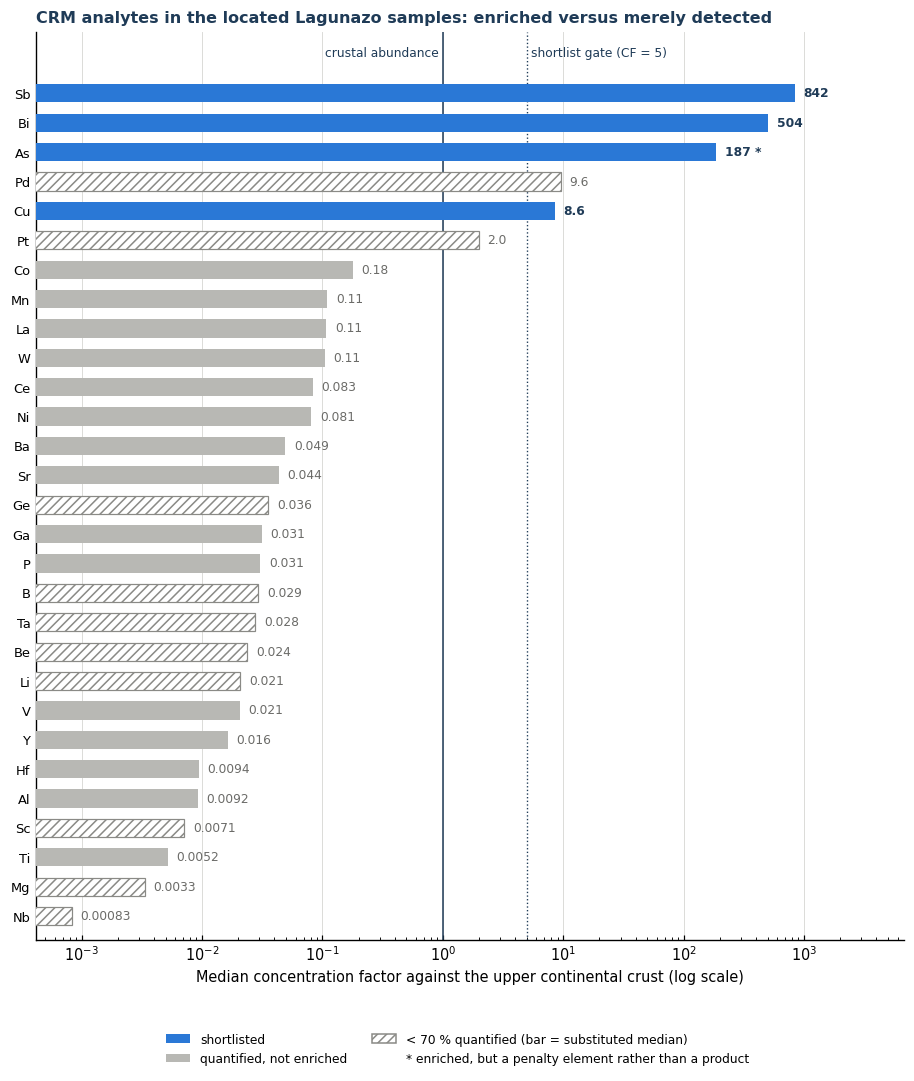

In [76]:
# Figure 1 - concentration factor of every CRM analyte (one measure, one log axis; status carried by fill + label)
def cf_label(x):
    return f"{x:,.0f}" if x >= 10 else (f"{x:.1f}" if x >= 1 else f"{x:.2g}")

_d = SCREEN_CRM.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8.4, 0.27 * len(_d) + 2.0))
for i, r in _d.iterrows():
    short = r["Status"].startswith("shortlisted")
    poor = r["Status"] == "insufficiently quantified"
    ax.barh(i, r["CF median"], left=0, height=0.62,
            color=(C_SERIES[0] if short else ("white" if poor else "#b8b8b4")),
            edgecolor=("#8a8a86" if poor else "none"), linewidth=0.8, hatch=("////" if poor else None), zorder=3)
    lab = cf_label(r["CF median"]) + (" *" if r["Element"] in DELETERIOUS else "")
    ax.text(r["CF median"] * 1.18, i, lab, va="center", ha="left", fontsize=8,
            color=C_INK if short else C_MUTED, fontweight="bold" if short else "normal")
ax.set_xscale("log")
ax.set_xlim(SCREEN_CRM["CF median"].min() * 0.5, SCREEN_CRM["CF median"].max() * 8)
ax.set_yticks(range(len(_d)))
ax.set_yticklabels(_d["Element"], fontsize=8.5)
ax.axvline(1.0, color=C_INK, lw=1.0, zorder=2)
ax.axvline(SHORTLIST_MIN_CF, color=C_INK, lw=0.9, ls=":", zorder=2)
ax.text(0.93, len(_d) + 0.15, "crustal abundance", fontsize=8, color=C_INK, va="bottom", ha="right")
ax.text(SHORTLIST_MIN_CF * 1.08, len(_d) + 0.15, f"shortlist gate (CF = {SHORTLIST_MIN_CF:g})", fontsize=8, color=C_INK,
        va="bottom", ha="left")
ax.set_ylim(-0.8, len(_d) + 1.1)
ax.grid(axis="x", color=C_GRID, lw=0.6, zorder=0)
ax.set_xlabel("Median concentration factor against the upper continental crust (log scale)")
ax.set_title("CRM analytes in the located Lagunazo samples: enriched versus merely detected", loc="left",
             fontweight="bold", color=C_INK)
_h = [Patch(fc=C_SERIES[0], label="shortlisted"), Patch(fc="#b8b8b4", label="quantified, not enriched"),
      Patch(fc="white", ec="#8a8a86", hatch="////", label=f"< {SHORTLIST_MIN_QUANT_PCT:g} % quantified (bar = substituted median)")]
if any(e in DELETERIOUS for e in SHORTLIST):
    _h.append(Line2D([0], [0], color="none", label="* enriched, but a penalty element rather than a product"))
fig.legend(handles=_h, loc="lower center", ncol=2, fontsize=8, frameon=False, bbox_to_anchor=(0.5, 0.0))
plt.tight_layout(rect=(0, 0.07, 1, 1))
savefig(fig, "Fig1_CRM_concentration_factors")
plt.show()

### 5.3 · What the shortlisted CRMs travel with

In [77]:
CO_PRODUCTS = [e for e in ("Pb", "Ag", "Au", "Zn", "Sn", "In", "Hg", "Se") if e in META.index]
rows = []
for el in CO_PRODUCTS:
    z, f = located_ppm(el)
    n_odl = int(np.sum(f == "odl"))
    rows.append({"Element": el, "n located": len(z), "n > UDL": n_odl,
                 "Median (ppm)": (">= " if n_odl >= len(z) / 2 else "") + fmt_num(float(np.median(z))),
                 "Max (ppm)": ("> " if n_odl else "") + fmt_num(float(np.max(z))),
                 "Crust (ppm)": fmt_num(UCC_PPM[el]),
                 "CF median": (">= " if n_odl >= len(z) / 2 else "") + fmt_num(float(np.median(z)) / UCC_PPM[el])})
CONTEXT_TABLE = pd.DataFrame(rows)
print("Non-CRM elements reported by the same package (context only; '>=' marks a lower bound set by the upper limit):")
show_table(CONTEXT_TABLE)
if "Pb_LF725" in RAW_VAL.columns:
    _pb = RAW_VAL.loc[has_lf & (RAW_FLAG["Pb_LF725"] == "ok"), "Pb_LF725"]
    print(f"Fusion XRF (total) Pb in the {len(_pb)} samples analysed by LF725: {_pb.min():g} - {_pb.max():g} %  "
          f"(median {_pb.median():g} %)")

_corr_els = RES_ELS + [e for e in ("Pb", "Ag", "Au", "Fe", "Zn") if e in META.index]
_q = {}
for el in _corr_els:
    f = RAW_FLAG.loc[has_any, el].to_numpy()[LOCATED]
    v = RAW_VAL.loc[has_any, el].to_numpy(float)[LOCATED]
    _q[el] = np.where(f == "ok", v, np.nan)
SPEARMAN = pd.DataFrame(_q).corr(method="spearman", min_periods=10)
_few = [c for c in SPEARMAN.columns if SPEARMAN[c].drop(c).isna().all()]
SPEARMAN = SPEARMAN.drop(index=_few, columns=_few)
if _few:
    print(f"\n(too few quantified values for a rank correlation: {', '.join(_few)} - mostly above the upper limit)")
print("\nSpearman rank correlation, located samples, quantified values only:")
display(SPEARMAN.round(2))
if all(e in SPEARMAN for e in ("Sb", "Bi", "Cu")):
    print(f"  Sb-Bi {SPEARMAN.loc['Sb', 'Bi']:+.2f}   |   Cu-Sb {SPEARMAN.loc['Cu', 'Sb']:+.2f}   Cu-Bi {SPEARMAN.loc['Cu', 'Bi']:+.2f}"
          + (f"   |   Bi-Au {SPEARMAN.loc['Bi', 'Au']:+.2f}   Sb-Au {SPEARMAN.loc['Sb', 'Au']:+.2f}" if "Au" in SPEARMAN else ""))
    if SPEARMAN.loc["Sb", "Bi"] > 0.5 and SPEARMAN.loc["Cu", "Bi"] < -0.3:
        print("  -> Sb and Bi rise and fall together and with the precious metals; Cu varies AGAINST them. The waste holds "
              "(at least) two materials:\n     a Sb-Bi(-Ag-Au) one and a Cu(-Zn-Fe) one. One variogram and one density "
              "for the whole polygon is therefore a simplification (Section 16).")

Non-CRM elements reported by the same package (context only; '>=' marks a lower bound set by the upper limit):


Element,n located,n > UDL,Median (ppm),Max (ppm),Crust (ppm),CF median
Pb,36,32,">= 10,000","> 10,000",17,>= 588.2
Ag,36,16,86.48,> 100,0.053,"1,632"
Au,36,0,0.7619,2.776,0.0015,507.9
Zn,36,0,346.6,"5,405",67,5.174
Sn,36,13,86.85,> 100,2.1,41.36
In,36,0,0.88,4,0.056,15.71
Hg,36,17,44.04,> 50,0.05,880.8
Se,36,9,36.35,> 100,0.09,403.9


Fusion XRF (total) Pb in the 8 samples analysed by LF725: 0.16 - 18.66 %  (median 2.125 %)

(too few quantified values for a rank correlation: Pb - mostly above the upper limit)

Spearman rank correlation, located samples, quantified values only:


,Fe,Ag,Au,Zn
Fe,1.00,-0.18,-0.58,0.41
Ag,-0.18,1.00,0.95,-0.32
Au,-0.58,0.95,1.00,-0.47
Zn,0.41,-0.32,-0.47,1.00


## 6 · Stage C Mapping Domain, DEM and the 193 m Base

The waste-area polygon is read exactly as in the OK notebook. The DEM is a USGS ASCII DEM; it is read here by a
small parser written out below, so the notebook does not depend on GDAL, and it is cross-checked against
`rasterio` when that library is installed.

In [78]:
def parse_kmz_boundary(kmz_path, epsg_out=EPSG_UTM):
    """Outer ring of the first polygon in a KMZ, projected to UTM; (None, None) if unavailable."""
    if not Path(kmz_path).exists():
        return None, None
    try:
        with zipfile.ZipFile(kmz_path) as z:
            kml_name = next(n for n in z.namelist() if n.endswith(".kml"))
            root = ET.fromstring(z.read(kml_name).decode("utf-8"))
        node = next((e for e in root.iter() if e.tag.endswith("outerBoundaryIs")), None)
        node = next((e for e in (node.iter() if node is not None else root.iter())
                     if e.tag.endswith("coordinates")), None)
        if node is None or not (node.text and node.text.strip()):
            print("  KMZ parse warning: no coordinate node found.")
            return None, None
        pts = [tuple(map(float, t.split(",")[:2])) for t in node.text.split() if len(t.split(",")) >= 2]
        if len(pts) < 3:
            return None, None
        xs, ys = lonlat_to_utm([p[0] for p in pts], [p[1] for p in pts], epsg=epsg_out)
        if not (xs[0] == xs[-1] and ys[0] == ys[-1]):
            xs, ys = np.append(xs, xs[0]), np.append(ys, ys[0])
        return xs, ys
    except Exception as e:
        print(f"  KMZ parse error: {e}")
        return None, None

XY_ALL = SAMP.loc[LOCATED, ["X_utm", "Y_utm"]].to_numpy(float)
px_utm, py_utm = parse_kmz_boundary(KMZ_FILE)
KMZ_LOADED = px_utm is not None
if KMZ_LOADED:
    print(f"KMZ boundary loaded: {len(px_utm) - 1} vertices")
elif SHAPELY_OK:
    _hull = MultiPoint([tuple(p) for p in XY_ALL]).convex_hull.buffer(60)
    px_utm, py_utm = map(np.array, _hull.exterior.coords.xy)
    print(f"'{KMZ_FILE}' not found - using the convex hull of the located ICP samples buffered by 60 m.")
else:
    from scipy.spatial import ConvexHull
    h = ConvexHull(XY_ALL)
    px_utm = np.append(XY_ALL[h.vertices, 0], XY_ALL[h.vertices[0], 0])
    py_utm = np.append(XY_ALL[h.vertices, 1], XY_ALL[h.vertices[0], 1])
    print(f"'{KMZ_FILE}' not found - using the plain convex hull of the located samples.")

BND_PATH = MPath(np.column_stack([px_utm, py_utm]))
if SHAPELY_OK:
    boundary_poly = ShapelyPolygon(zip(px_utm, py_utm))
    boundary_poly = boundary_poly if boundary_poly.is_valid else boundary_poly.buffer(0)
    print(f"  Boundary area: {boundary_poly.area / 1e4:.2f} ha")
else:
    boundary_poly = None

def inside_domain(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    if SHAPELY_OK and hasattr(shapely, "contains_xy"):
        return shapely.contains_xy(boundary_poly, x, y)
    return BND_PATH.contains_points(np.column_stack([x, y]))

SAMP["In_domain"] = False
SAMP.loc[LOCATED, "In_domain"] = inside_domain(XY_ALL[:, 0], XY_ALL[:, 1])
xmin_u, xmax_u = float(px_utm.min()), float(px_utm.max())
ymin_u, ymax_u = float(py_utm.min()), float(py_utm.max())
pad_x, pad_y = (xmax_u - xmin_u) * PAD_FRAC, (ymax_u - ymin_u) * PAD_FRAC
BND_LABEL = "Waste polygon" if KMZ_LOADED else "60 m buffered hull"
BND_LEGEND = "Waste boundary" if KMZ_LOADED else "Mapping domain"
n_out = int((SAMP.loc[LOCATED, "In_domain"] == False).sum())
print(f"  Located samples outside the domain: {n_out}"
      + (f" -> {', '.join(SAMP.loc[LOCATED & ~SAMP['In_domain'], 'Sample'])}" if n_out else ""))


KMZ boundary loaded: 146 vertices
  Boundary area: 16.25 ha
  Located samples outside the domain: 1 -> LA-25-03


In [79]:
from scipy import ndimage as ndi

def read_usgs_dem(path):
    """Read a USGS ASCII DEM (record A header + one record B per profile, 1024-byte blocks).
    Profiles run south -> north and are ordered west -> east; each carries its own starting northing, so profiles of
    different length are placed on one lattice. Returns (header, x[nx], y[ny] north -> south, Z[ny, nx] with NaN voids)."""
    raw = Path(path).read_bytes().decode("ascii", errors="replace")
    fl = lambda s: float(s.replace("D", "E"))
    A = raw[:1024]
    hdr = dict(ref_sys=int(A[156:162]), zone=int(A[162:168]), xy_unit=int(A[528:534]), z_unit=int(A[534:540]),
               corners=[(fl(A[546 + 48 * k:570 + 48 * k]), fl(A[570 + 48 * k:594 + 48 * k])) for k in range(4)],
               zmin=fl(A[738:762]), zmax=fl(A[762:786]),
               dx=float(A[816:828]), dy=float(A[828:840]), dz=float(A[840:852]), n_profiles=int(A[858:864]))
    pos, profs = 1024, []
    for _ in range(hdr["n_profiles"]):
        B = raw[pos:pos + 1024]
        m = int(B[12:18])                                         # number of elevations in this profile
        xgo, ygo, datum = fl(B[24:48]), fl(B[48:72]), fl(B[72:96])
        vals = [int(B[144 + 6 * k:150 + 6 * k]) for k in range(min(m, 146))]
        pos += 1024
        while len(vals) < m:                                      # continuation blocks hold 170 values each
            B = raw[pos:pos + 1024]
            vals += [int(B[6 * k:6 * k + 6]) for k in range(min(m - len(vals), 170))]
            pos += 1024
        profs.append((xgo, ygo, datum, np.asarray(vals, float)))
    hdr["bytes_read"], hdr["bytes_total"] = pos, len(raw)
    dx, dy = hdr["dx"], hdr["dy"]
    full = [p for p in profs if len(p[3])]
    y_min = min(p[1] for p in full)
    y_max = max(p[1] + (len(p[3]) - 1) * dy for p in full)
    ny, nx = int(round((y_max - y_min) / dy)) + 1, len(profs)
    Z = np.full((ny, nx), np.nan)
    for j, (x0, y0, datum, v) in enumerate(profs):
        if not len(v):
            continue
        k0 = (y0 - y_min) / dy
        if abs(k0 - round(k0)) > 1e-6:
            raise ValueError("DEM profiles do not share one northing lattice.")
        k = int(round(k0)) + np.arange(len(v))
        ok = v > -32000                                           # void value is -32767
        Z[ny - 1 - k[ok], j] = v[ok] * hdr["dz"] + datum
    x = np.array([p[0] for p in profs])
    if not np.allclose(np.diff(x), dx, atol=1e-6):
        raise ValueError("DEM profiles are not equally spaced in easting.")
    return hdr, x, y_max - np.arange(ny) * dy, Z

DEM_HDR, DEM_X, DEM_Y, DEM_Z = read_usgs_dem(DEM_FILE)
DX, DY, DZ_STEP = DEM_HDR["dx"], DEM_HDR["dy"], DEM_HDR["dz"]
CELL_AREA = DX * DY
if not (DEM_HDR["ref_sys"] == 1 and DEM_HDR["zone"] == int(EPSG_UTM[-2:]) and DEM_HDR["xy_unit"] == 2 and DEM_HDR["z_unit"] == 2):
    raise ValueError(f"DEM is not UTM zone {EPSG_UTM[-2:]} in metres: {DEM_HDR}")
VALID = np.isfinite(DEM_Z)
_XX, _YY = np.meshgrid(DEM_X, DEM_Y)
xv, yv, zv = _XX[VALID], _YY[VALID], DEM_Z[VALID]
DEM_AREA = VALID.sum() * CELL_AREA
_in = inside_domain(xv, yv)
_levels = np.unique(zv)

print(f"DEM  : {DEM_Z.shape[1]} x {DEM_Z.shape[0]} nodes at {DX:g} m, {int(VALID.sum()):,} with data "
      f"({DEM_AREA / 1e4:.2f} ha); file fully parsed: {DEM_HDR['bytes_read'] == DEM_HDR['bytes_total']}")
print(f"       UTM zone {DEM_HDR['zone']}, metres; E {DEM_X.min():.1f}-{DEM_X.max():.1f}, N {DEM_Y.min():.1f}-{DEM_Y.max():.1f}")
print(f"       elevation {zv.min():g} - {zv.max():g} m in the data (header: {DEM_HDR['zmin']:g} - {DEM_HDR['zmax']:g} m); "
      f"vertical step {DZ_STEP:g} m -> {len(_levels)} distinct levels")
print(f"       against the KMZ polygon ({boundary_poly.area / 1e4:.2f} ha): {int((~_in).sum()):,} DEM nodes "
      f"({(~_in).sum() * CELL_AREA:,.0f} m2) fall outside it -> the DEM was clipped with this polygon and the two agree "
      f"to {100 * abs(DEM_AREA - boundary_poly.area) / boundary_poly.area:.2f} % in area")

DEM_CROSSCHECK = "rasterio not installed - independent read skipped"
try:
    import rasterio
    with rasterio.open(DEM_FILE) as _ds:
        _z = _ds.read(1).astype(float)
        _z[_z == _ds.nodata] = np.nan
        _t = _ds.transform
    # GDAL builds its lattice from the header corners and snaps profile origins to it; align the two by position
    _r0 = int(round(((_t.f + 0.5 * _t.e) - DEM_Y[0]) / DY))
    _c0 = int(round((DEM_X[0] - (_t.c + 0.5 * _t.a)) / DX))
    _sub = _z[_r0:_r0 + DEM_Z.shape[0], _c0:_c0 + DEM_Z.shape[1]]
    _same = (_sub.shape == DEM_Z.shape and int(np.isfinite(_z).sum()) == int(np.isfinite(_sub).sum())
             and np.array_equal(np.isnan(_sub), np.isnan(DEM_Z)) and float(np.nanmax(np.abs(_sub - DEM_Z))) == 0.0)
    _dyo = DEM_Y[0] - (_t.f + (_r0 + 0.5) * _t.e)
    _dxo = DEM_X[0] - (_t.c + (_c0 + 0.5) * _t.a)
    DEM_CROSSCHECK = (f"all {int(np.isfinite(_sub).sum()):,} elevations identical to the GDAL/rasterio read: {_same}; GDAL snaps the "
                      f"profile origins to its own lattice, {_dxo:+.3f} m E and {_dyo:+.3f} m N of the positions stored in the file "
                      f"(the stored positions are used here)")
    DEM_SAME = bool(_same)
except ImportError:
    DEM_SAME = None
except Exception as _e:                       # e.g. a GDAL / PROJ installation problem: not an error of this notebook
    DEM_SAME, DEM_CROSSCHECK = None, f"rasterio could not open the DEM ({str(_e)[:80]}) - independent read skipped"
print(f"       cross-check: {DEM_CROSSCHECK}")

# elevation of every located sample (nearest DEM node)
_tree = cKDTree(np.column_stack([xv, yv]))
_d, _i = _tree.query(SAMP.loc[LOCATED, ["X_utm", "Y_utm"]].to_numpy(float))
SAMP["DEM_z"] = np.nan
SAMP.loc[LOCATED, "DEM_z"] = np.where(_d <= 2 * max(DX, DY), zv[_i], np.nan)
print(f"Samples: surface elevation {np.nanmin(SAMP['DEM_z']):g} - {np.nanmax(SAMP['DEM_z']):g} m; "
      f"{int(SAMP.loc[LOCATED, 'DEM_z'].isna().sum())} located sample(s) lie off the DEM "
      f"({', '.join(SAMP.loc[LOCATED & SAMP['DEM_z'].isna().to_numpy(), 'Sample']) or '-'})")

DEM  : 1149 x 1054 nodes at 0.5 m, 649,983 with data (16.25 ha); file fully parsed: True
       UTM zone 29, metres; E 661412.6-661986.6, N 4165350.2-4165876.7
       elevation 193 - 213 m in the data (header: 193 - 214 m); vertical step 1 m -> 21 distinct levels
       against the KMZ polygon (16.25 ha): 1 DEM nodes (0 m2) fall outside it -> the DEM was clipped with this polygon and the two agree to 0.00 % in area
       cross-check: all 649,983 elevations identical to the GDAL/rasterio read: True; GDAL snaps the profile origins to its own lattice, +0.000 m E and +0.154 m N of the positions stored in the file (the stored positions are used here)
Samples: surface elevation 194 - 209 m; 1 located sample(s) lie off the DEM (LA-25-03)


### 6.1 · Base elevation, thickness and volume

In [80]:
Z_BASE = float(BASE_ELEVATION_M)
_below = int(np.sum(zv < Z_BASE))
SCENARIOS = {"A": dict(label=f"Base case - horizontal base at {Z_BASE:g} m a.s.l., thickness = DEM - {Z_BASE:g} m",
                       short=f"base {Z_BASE:g} m", base=np.full_like(zv, Z_BASE))}
BASE_CASE = "A"
for s in SCENARIOS.values():
    s["th"] = np.clip(zv - s["base"], 0.0, None)        # thickness per DEM node, m
    s["volume"] = float(s["th"].sum() * CELL_AREA)      # m3
TH = SCENARIOS["A"]["th"]
TH_MEAN = float(TH.mean())
VOL_Q = 0.5 * DZ_STEP * DEM_AREA                        # volume equivalent of the DEM's vertical rounding
CASE_LABEL = {"A": f"DEM thickness on the {Z_BASE:g} m base (base case)", "U": f"uniform slab, {TH_MEAN:.2f} m everywhere"}

# margin of the polygon = valid nodes with a void (or the array edge) among their 8 neighbours
RING = VALID & ~ndi.binary_erosion(VALID, structure=np.ones((3, 3)), border_value=0)
zr = DEM_Z[RING]

_bands = [(0, 5), (5, 10), (10, 15), (15, 99)]
rows = [{"Thickness class (m)": f"{a}-{b}" if b < 99 else f"> {a}", "Area (ha)": float(np.sum((TH >= a) & (TH < b)) * CELL_AREA / 1e4),
         "Volume (Mm3)": float(TH[(TH >= a) & (TH < b)].sum() * CELL_AREA / 1e6)} for a, b in _bands]
rows.append({"Thickness class (m)": "all", "Area (ha)": DEM_AREA / 1e4, "Volume (Mm3)": SCENARIOS["A"]["volume"] / 1e6})
VOLUME_TABLE = pd.DataFrame(rows)
VOLUME_TABLE["Share of volume (%)"] = 100 * VOLUME_TABLE["Volume (Mm3)"] / (SCENARIOS["A"]["volume"] / 1e6)
show_table(VOLUME_TABLE, precision=3)

print(f"Base        : {Z_BASE:g} m a.s.l.; lowest elevation in the DEM {zv.min():g} m"
      + (" (identical: the base touches the surface at its lowest point)" if zv.min() == Z_BASE else "")
      + (f"; {_below:,} DEM nodes lie below the base and are given zero thickness" if _below else ""))
print(f"Volume      : {SCENARIOS['A']['volume'] / 1e6:.3f} Mm3 over {DEM_AREA / 1e4:.2f} ha; thickness {TH.min():g} - {TH.max():g} m, "
      f"mean {TH_MEAN:.2f} m, median {np.median(TH):g} m")
print(f"Uniform slab: {DEM_AREA / 1e4:.2f} ha x {TH_MEAN:.2f} m = {DEM_AREA * TH_MEAN / 1e6:.3f} Mm3 (the same volume by construction)")
print(f"DEM rounding: elevations are stored in {DZ_STEP:g} m steps, so the surface-to-base distance is known to +/- {0.5 * DZ_STEP:g} m "
      f"on average -> +/- {VOL_Q / 1e6:.3f} Mm3 (+/- {100 * VOL_Q / SCENARIOS['A']['volume']:.1f} %)")
print(f"Implication : at the margin of the polygon the surface stands at {zr.min():g} - {zr.max():g} m (mean {zr.mean():.1f} m), so the "
      f"base case carries {zr.mean() - Z_BASE:.1f} m of waste\n              on average right up to the boundary. The waste is taken to "
      "end against the boundary at full thickness, not to thin out towards it.")

Thickness class (m),Area (ha),Volume (Mm3),Share of volume (%)
0-5,0.660,0.015,0.822
5-10,6.062,0.431,24.208
10-15,5.442,0.675,37.909
> 15,4.086,0.660,37.061
all,16.250,1.780,100.000


Base        : 193 m a.s.l.; lowest elevation in the DEM 193 m (identical: the base touches the surface at its lowest point)
Volume      : 1.780 Mm3 over 16.25 ha; thickness 0 - 20 m, mean 10.96 m, median 11 m
Uniform slab: 16.25 ha x 10.96 m = 1.780 Mm3 (the same volume by construction)
DEM rounding: elevations are stored in 1 m steps, so the surface-to-base distance is known to +/- 0.5 m on average -> +/- 0.081 Mm3 (+/- 4.6 %)
Implication : at the margin of the polygon the surface stands at 193 - 213 m (mean 203.8 m), so the base case carries 10.8 m of waste
              on average right up to the boundary. The waste is taken to end against the boundary at full thickness, not to thin out towards it.


### 6.2 · Block model

The 3 m lattice of the OK and IDW notebooks is kept, so the rasters remain co-registered. Every DEM node is assigned
to its nearest lattice node; a block's area, mean surface elevation and volume are sums over its DEM nodes. The
total volume is therefore conserved exactly, which the audit in Section 14 verifies.

In [81]:
G = float(GRID_DENSITY_M)
_ix = np.rint((xv - xmin_u) / G).astype(np.int64)
_iy = np.rint((yv - ymin_u) / G).astype(np.int64)
if _ix.min() < 0 or _iy.min() < 0:
    raise ValueError("DEM extends beyond the polygon's bounding box - check that the DEM and the KMZ belong together.")
NCOL, NROW = int(_ix.max()) + 1, int(_iy.max()) + 1
_key, BLK_INV = np.unique(_iy * NCOL + _ix, return_inverse=True)
BLK_INV = np.asarray(BLK_INV).ravel()
BLK_IX, BLK_IY = _key % NCOL, _key // NCOL
BLK_XY = np.column_stack([xmin_u + BLK_IX * G, ymin_u + BLK_IY * G])
BLK_N = np.bincount(BLK_INV)
BLK_AREA = BLK_N * CELL_AREA
BLK_Z = np.bincount(BLK_INV, weights=zv) / BLK_N
BLK_VOL = {"A": np.bincount(BLK_INV, weights=TH * CELL_AREA),      # base case: thickness from the DEM
           "U": BLK_AREA * TH_MEAN}                                # uniform slab: one thickness everywhere
BLK_TH = {k: BLK_VOL[k] / BLK_AREA for k in BLK_VOL}
NB = len(BLK_AREA)
XG = xmin_u + np.arange(NCOL) * G
YG = ymin_u + np.arange(NROW) * G

def to_grid(vals):
    """Block values -> (NROW, NCOL) raster, row 0 = south, NaN outside the model."""
    g = np.full(NROW * NCOL, np.nan)
    g[_key] = vals
    return g.reshape(NROW, NCOL)

print(f"Block model: {NB:,} blocks of {G:g} x {G:g} m on a {NCOL} x {NROW} lattice; {int((BLK_N < (G / DX) * (G / DY)).sum()):,} "
      f"partial blocks along the margin")
print(f"  area {BLK_AREA.sum() / 1e4:.3f} ha   |   volume {BLK_VOL['A'].sum() / 1e6:.4f} Mm3 (base case)   "
      f"{BLK_VOL['U'].sum() / 1e6:.4f} Mm3 (uniform slab)")
for dname, rho in BULK_DENSITY.items():
    print(f"  tonnage at {rho:.2f} t/m3 ({dname:4s}): {rho * BLK_VOL['A'].sum() / 1e6:5.2f} Mt")

Block model: 18,399 blocks of 3 x 3 m on a 192 x 177 lattice; 675 partial blocks along the margin
  area 16.250 ha   |   volume 1.7802 Mm3 (base case)   1.7802 Mm3 (uniform slab)
  tonnage at 1.10 t/m3 (low ):  1.96 Mt
  tonnage at 1.25 t/m3 (base):  2.23 Mt
  tonnage at 1.40 t/m3 (high):  2.49 Mt


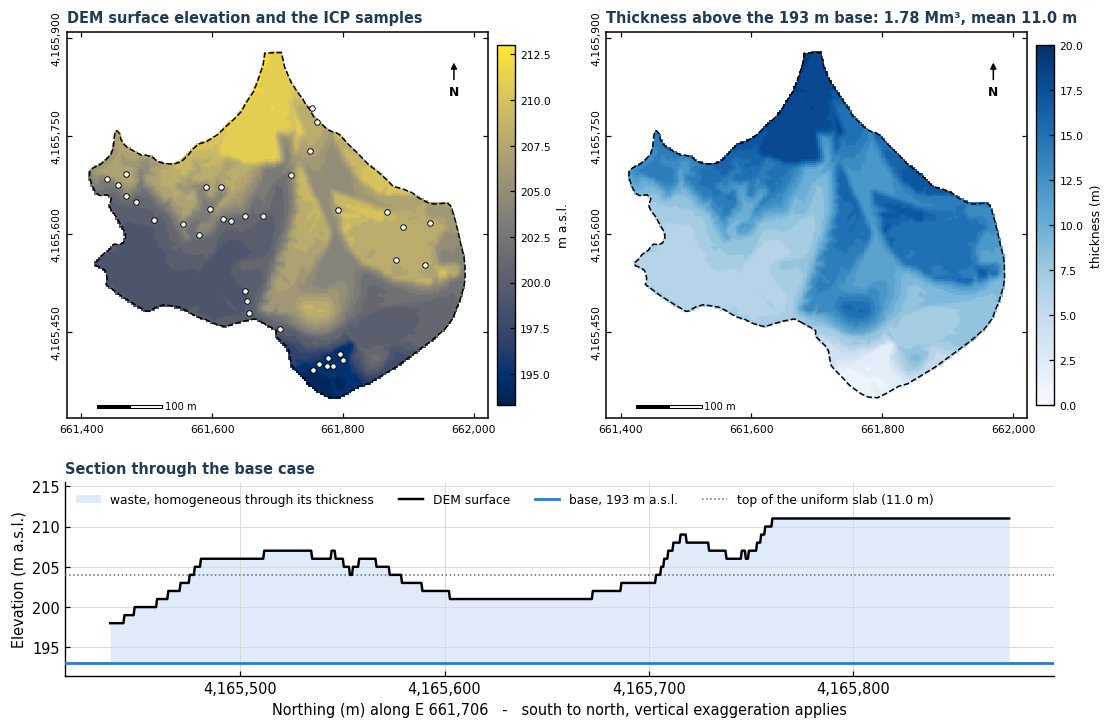

In [82]:
# Figure 2 - surface, thickness above the 193 m base, and a south-north section
EXTENT = [XG[0] - G / 2, XG[-1] + G / 2, YG[0] - G / 2, YG[-1] + G / 2]
pad_x, pad_y = (xmax_u - xmin_u) * PAD_FRAC, (ymax_u - ymin_u) * PAD_FRAC

def map_frame(ax, title=None, scale_bar=True, north=True, ylabels=True):
    """Neatline, boundary, plain UTM ticks, scale bar and north arrow."""
    for s in ax.spines.values():
        s.set_visible(True); s.set_linewidth(1.0); s.set_color("black")
    ax.plot(px_utm, py_utm, color="black", lw=1.0, ls="--", zorder=8)
    ax.set_xlim(xmin_u - pad_x, xmax_u + pad_x); ax.set_ylim(ymin_u - pad_y, ymax_u + pad_y)
    ax.set_aspect("equal", adjustable="box")
    ax.xaxis.set_major_locator(mticker.MaxNLocator(4)); ax.yaxis.set_major_locator(mticker.MaxNLocator(4))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.tick_params(labelsize=7, top=True, right=True, length=3)
    for lab in ax.get_yticklabels():
        lab.set_rotation(90); lab.set_va("center")
    if not ylabels:
        ax.set_yticklabels([])
    if title:
        ax.set_title(title, loc="left", fontweight="bold", color=C_INK, fontsize=9.5)
    if scale_bar:
        sx, sy = xmin_u + 0.02 * (xmax_u - xmin_u), ymin_u - 0.5 * pad_y
        for i in range(2):
            ax.add_patch(Rectangle((sx + 50 * i, sy), 50, 5, fc="black" if i == 0 else "white", ec="black", lw=0.7, zorder=9))
        ax.text(sx + 104, sy + 2.5, "100 m", fontsize=6.5, va="center", ha="left", zorder=9)
    if north:
        nx_, ny_ = xmax_u - 0.03 * (xmax_u - xmin_u), ymax_u - 0.02 * (ymax_u - ymin_u)
        ax.annotate("N", xy=(nx_, ny_), xytext=(nx_, ny_ - 50), ha="center", va="center", fontsize=8, fontweight="bold",
                    arrowprops=dict(arrowstyle="-|>", color="black", lw=1.0), zorder=9)

_sx, _sy = SAMP.loc[LOCATED, "X_utm"].to_numpy(float), SAMP.loc[LOCATED, "Y_utm"].to_numpy(float)
_aq = (LOCATED & has_aq[has_any].to_numpy())[LOCATED]
_thmax = float(np.ceil(BLK_TH["A"].max()))

fig = plt.figure(figsize=(11.6, 7.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 0.50], hspace=0.22, wspace=0.20)
ax = fig.add_subplot(gs[0, 0])
im = ax.imshow(to_grid(BLK_Z), extent=EXTENT, origin="lower", cmap="cividis", interpolation="nearest", zorder=1)
ax.scatter(_sx[_aq], _sy[_aq], s=13, c="white", edgecolors="black", linewidths=0.6, zorder=10)
map_frame(ax, "DEM surface elevation and the ICP samples")
cb = fig.colorbar(im, ax=ax, fraction=0.040, pad=0.02); cb.set_label("m a.s.l.", fontsize=8); cb.ax.tick_params(labelsize=7)
ax = fig.add_subplot(gs[0, 1])
im = ax.imshow(to_grid(BLK_TH["A"]), extent=EXTENT, origin="lower", cmap="Blues", vmin=0, vmax=_thmax, interpolation="nearest", zorder=1)
map_frame(ax, f"Thickness above the {Z_BASE:g} m base: {SCENARIOS['A']['volume'] / 1e6:.2f} Mm³, mean {TH_MEAN:.1f} m")
cb = fig.colorbar(im, ax=ax, fraction=0.040, pad=0.02); cb.set_label("thickness (m)", fontsize=8); cb.ax.tick_params(labelsize=7)

# south-north section along the DEM column with the longest run of data
_jc = int(np.argmax(VALID.sum(axis=0)))
_rows = np.flatnonzero(VALID[:, _jc])
_ysec, _zsec = DEM_Y[_rows], DEM_Z[_rows, _jc]
ax = fig.add_subplot(gs[1, :])
ax.fill_between(_ysec, np.full_like(_zsec, Z_BASE), _zsec, color=C_SERIES[0], alpha=0.14, lw=0, zorder=1,
                label="waste, homogeneous through its thickness")
ax.plot(_ysec, _zsec, color="black", lw=1.6, label="DEM surface", zorder=5)
ax.axhline(Z_BASE, color=C_SERIES[0], lw=1.8, label=f"base, {Z_BASE:g} m a.s.l.", zorder=4)
ax.axhline(Z_BASE + TH_MEAN, color=C_MUTED, lw=1.0, ls=":", label=f"top of the uniform slab ({TH_MEAN:.1f} m)", zorder=3)
ax.set_xlabel(f"Northing (m) along E {DEM_X[_jc]:,.0f}   -   south to north, vertical exaggeration applies")
ax.set_ylabel("Elevation (m a.s.l.)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.grid(color=C_GRID, lw=0.6)
ax.set_ylim(Z_BASE - 1.5, float(_zsec.max()) + 4.5)
ax.legend(ncol=4, fontsize=8, frameon=False, loc="upper left")
ax.set_title("Section through the base case", loc="left", fontweight="bold", color=C_INK, fontsize=9.5)
savefig(fig, "Fig2_DEM_thickness_base_193m")
plt.show()

## 7 · Stage D - Stations of the Shortlisted CRMs

The located assays of each shortlisted element are collapsed to stations (replicates within 5 m), exactly as in the
OK notebook, and declustered. All grades from here on are in ppm (g/t). Two properties of the data matter for
everything that follows and are therefore tabulated: how many stations exceed the upper reporting limit (their
value is a lower bound), and how many lie outside the waste polygon.

In [83]:
def element_points(el):
    """Located samples with an assay for `el`; censored values substituted, flag kept."""
    f = RAW_FLAG.loc[has_any, el].to_numpy()
    v = RAW_VAL.loc[has_any, el].to_numpy(float)
    z = np.where(f == "ok", v, np.where(f == "bdl", BDL_FACTOR * v, np.where(f == "odl", ODL_FACTOR * v, np.nan)))
    d = pd.DataFrame({"Sample": SAMP["Sample"].to_numpy(), "X_utm": SAMP["X_utm"].to_numpy(),
                      "Y_utm": SAMP["Y_utm"].to_numpy(), el: z, "flag": f})
    return d[LOCATED & np.isfinite(z)].reset_index(drop=True)

def unit_of(el):
    return META.loc[el, "unit"]

def is_partial(el):
    return digestion_class(el).startswith("partial")


In [84]:
# pXRF override (Pb and Fe): stations come from the pXRF sample-level dataset, not from the ICP workbook.
# Same rules as Part B of Final_pXRF_samples_mapping_r4.ipynb: '<LOD' -> missing, readings of one sample combined
# by their median, sample IDs matched on a normalised key (upper case, separators removed, LA20xx -> LAxx).
PXRF_FILE   = "XRF_Lagunazo_complete_r2.csv"
PXRF_COORDS = "Lagunazo_UTM.csv"          # columns ID, X, Y (UTM 29N)

def _pkey(v):
    s = re.sub(r"[-_/.]", "", str(v).strip().upper().replace(" ", ""))
    return re.sub(r"^LA20(\d\d)", r"LA\1", s)

def _pnum(series):
    t = series.astype("string").str.strip()
    bad = t.str.startswith("<", na=False) | t.str.contains("LOD", case=False, na=False)
    return pd.to_numeric(t.mask(bad, pd.NA), errors="coerce").astype("float64")

_r = pd.read_csv(PXRF_FILE); _r.columns = [str(c).strip() for c in _r.columns]
_v = pd.DataFrame({e: _pnum(_r[e]) for e in ("Pb", "Fe")}); _v["key"] = _r["Sample"].map(_pkey).to_numpy()
PX = _v.groupby("key")[["Pb", "Fe"]].median()
_c = pd.read_csv(PXRF_COORDS); _c["key"] = _c["ID"].map(_pkey)
PX = PX.join(_c.drop_duplicates("key").set_index("key")[["X", "Y"]].rename(columns={"X": "E", "Y": "N"}))
PX = PX[PX["E"].notna()].copy()

def element_points(el):
    d = pd.DataFrame({"Sample": PX.index.to_numpy(), "X_utm": PX["E"].to_numpy(float), "Y_utm": PX["N"].to_numpy(float),
                      el: PX[el].to_numpy(float), "flag": "ok"})
    return d[np.isfinite(d[el])].reset_index(drop=True)

def unit_of(el):
    return "ppm"

print("pXRF override:", {e: int(PX[e].notna().sum()) for e in ("Pb", "Fe")}, "located samples")


pXRF override: {'Pb': 84, 'Fe': 84} located samples


In [85]:
STATIONS, rows = {}, []
for el in RES_ELS:
    pe = element_points(el)
    st, srep = station_means(pe, "X_utm", "Y_utm", el, tol_m=STATION_TOL_M, id_col="Sample", flag_col="flag")
    coords = st[["X_utm", "Y_utm"]].to_numpy(float)
    v = st[el].to_numpy(float) * TO_PPM[unit_of(el)]
    n = len(v)
    if n < MIN_STATIONS or n * (n - 1) // 2 < MIN_PAIRS_TOTAL or len(np.unique(v)) < MIN_DISTINCT_VALS:
        raise ValueError(f"{el}: too few stations or distinct values for a variogram ({n} stations).")
    w, cell, _ = declustering_weights(coords, v)
    inside = np.asarray(inside_domain(coords[:, 0], coords[:, 1]), bool)
    odl = st["flag"].str.contains("odl").to_numpy()
    bdl = st["flag"].str.contains("bdl").to_numpy()
    sd = float(np.std(v, ddof=1))
    imax = int(np.argmax(np.abs(v - v.mean())))
    STATIONS[el] = dict(coords=coords, v=v, st=st, w=w, inside=inside, odl=odl, bdl=bdl,
                        spacing=float(np.median(cKDTree(coords).query(coords, k=2)[0][:, 1])),
                        ex_d=float(cKDTree(coords).query(coords, k=2)[0][:, 1].max()))
    rows.append({"Element": el, "Stations": n, "Replicate stations": srep["n_stations_with_reps"],
                 "> UDL": int(odl.sum()), "< MDL": int(bdl.sum()), "Outside polygon": int((~inside).sum()),
                 "Mean (ppm)": v.mean(), "Median (ppm)": float(np.median(v)), "Min": v.min(), "Max": v.max(),
                 "CV": sd / v.mean(), "Skewness": float(stats.skew(v)),
                 "Cell-declustered mean": float(np.sum(w * v) / w.sum()), "Declustering cell (m)": cell,
                 "Top-1 share of variance": float(((v[imax] - v.mean()) ** 2 / (n - 1)) / sd ** 2)})
STATION_TABLE = pd.DataFrame(rows)
show_table(STATION_TABLE, precision=3)
for el in RES_ELS:
    S = STATIONS[el]
    if S["odl"].any():
        print(f"  {el}: {int(S['odl'].sum())} station(s) above the upper reporting limit "
              f"({', '.join(S['st'].loc[S['odl'], 'Sample'])}) are held AT the limit -> the {el} grades below are lower bounds.")
_out = STATIONS[RES_ELS[0]]
if (~_out["inside"]).any():
    _c = _out["coords"][~_out["inside"]]
    _dist = [boundary_poly.exterior.distance(Point(*c)) for c in _c] if SHAPELY_OK else [np.nan] * len(_c)
    print(f"  Outside the polygon: {', '.join(_out['st'].loc[~_out['inside'], 'Sample'])} "
          f"({', '.join(f'{d:.1f} m' for d in _dist)} from the boundary - comparable with the ~3 m positional precision of the "
          f"coordinates; kept, and tested in the sensitivity analysis).")

Element,Stations,Replicate stations,> UDL,< MDL,Outside polygon,Mean (ppm),Median (ppm),Min,Max,CV,Skewness,Cell-declustered mean,Declustering cell (m),Top-1 share of variance
Pb,68,4,0,0,1,25416.869,19800.512,312.482,106790.441,0.905,1.545,22225.903,61.1,0.187
Fe,68,4,0,0,1,168111.819,144935.383,1204.075,458219.719,0.758,0.580,154278.003,175.4,0.077


  Outside the polygon: LMW21 (2.0 m from the boundary - comparable with the ~3 m positional precision of the coordinates; kept, and tested in the sensitivity analysis).


## 8 · Stage D Variogram, Model and Transform Selection, Nested Cross-Validation

The two cells below are the Stage-2 and nested cross-validation routines of the OK notebook, verbatim. For each
element and transform the experimental variogram uses equal-count lags of at least 30 pairs up to half the largest
station separation; five models are fitted, each is cross-validated, and the model and then the transform are
selected. The **nested** cross-validation repeats that whole selection without each station in turn and is the
only skill measure used for decisions here, because the ordinary leave-one-out R² is inflated by choosing among
fifteen candidates with the same errors that it reports.

In [86]:
def _max_sep(c):
    return float(np.max(np.hypot(c[:, None, 0] - c[None, :, 0], c[:, None, 1] - c[None, :, 1])))

def _spacing(c):
    return float(np.median(cKDTree(c).query(c, k=2)[0][:, 1]))

def analyse_core(coords, v, w, transform, label=""):
    """Transform -> variogram -> 5 model fits -> LOOCV each -> model choice -> LOOCV metrics in grade units.
    Works on plain arrays so that the nested cross-validation can re-run it without any held-out station."""
    spacing = _spacing(coords)
    tf = Transform(transform).fit(v, w=w)
    y = tf.forward(v)
    cutoff = CUTOFF_FACTOR * _max_sep(coords)
    vgm = experimental_variogram(coords, y, cutoff)
    out = dict(transform=transform, tf=tf, y=y, vgm=vgm, cutoff=cutoff, spacing=spacing,
               sample_variance=float(np.var(y, ddof=1)))
    if len(vgm) < 3:
        out["status"] = f"only {len(vgm)} lag(s) with >= {MIN_PAIRS_LAG} pairs"
        return out
    res = []
    for model, hits, wrss in fit_models(vgm, cutoff):
        radius = search_radius_for(model, spacing)
        cv = ok_batch(coords, coords, y, model, radius=radius, exclude_self=True)
        err = cv["est"] - y
        rmse = float(np.sqrt(np.mean(err ** 2)))
        pos = cv["var"] > 0
        rmsse = float(np.sqrt(np.mean(err[pos] ** 2 / cv["var"][pos]))) if pos.any() else np.nan
        score = rmse * (1 + RMSSE_PENALTY * abs((rmsse if np.isfinite(rmsse) else 1.0) - 1.0))
        res.append(dict(model=model, hits=hits, wrss=wrss, radius=radius, cv=cv,
                        rmse_fit=rmse, rmsse=rmsse, score=score))
    res.sort(key=lambda r: r["score"])
    tied = [r for r in res if r["score"] <= res[0]["score"] * (1 + SELECTION_TOL_PCT / 100)]
    best = sorted(tied, key=lambda r: MODEL_PREFERENCE.index(r["model"].name))[0]
    cv = best["cv"]
    pred = cv["est"] if transform == "none" else tf.back(cv["est"], var=cv["var"], mu=cv["mu"])
    n_clip = int(np.sum(pred < 0))
    pred = np.clip(pred, 0.0, None)
    m = metrics(v, pred, label=f"OK LOOCV {label} ({transform})")
    z = (cv["est"] - y) / np.sqrt(np.maximum(cv["var"], 1e-300))
    nug = next(r for r in res if r["model"].name == "Nugget")
    out.update(status="ok", results=res, tied=[r["model"].name for r in tied], best=best, model=best["model"],
               radius=best["radius"], pred_ppm=pred, n_clip_cv=n_clip, m=m, rmse_ppm=m["RMSE"], r2_ppm=m["R2_pred"],
               rmse_fit=best["rmse_fit"], rmsse=best["rmsse"],
               coverage95=float(100 * np.mean(np.abs(z) <= 1.959964)), mean_std_err=float(np.mean(z)),
               gain_vs_nugget_pct=100 * (nug["rmse_fit"] - best["rmse_fit"]) / nug["rmse_fit"],
               bound_hits=", ".join(best["hits"]), n_extended_cv=int(cv["extended"].sum()))
    return out


def analyse(el, transform):
    S = STATIONS[el]
    out = analyse_core(S["coords"], S["v"], S["w"], transform, label=el)
    out["element"] = el
    return out


def gain_pct(base, chal):
    """Improvement of `chal` over `base` for an error measure (lower is better), normalised by |base|."""
    return 100.0 * (base - chal) / max(abs(base), 1e-12)


def select_transform(cands):
    """Lowest back-transformed LOOCV RMSE; a transform must beat 'none' by TRANSFORM_MIN_GAIN_PCT."""
    ok_ = {t: a for t, a in cands.items() if a["status"] == "ok"}
    if not ok_:
        return None
    pick = min(ok_.values(), key=lambda a: a["rmse_ppm"])
    g = np.nan
    if "none" in ok_ and pick["transform"] != "none":
        g = gain_pct(ok_["none"]["rmse_ppm"], pick["rmse_ppm"])
        if g < TRANSFORM_MIN_GAIN_PCT:
            pick = ok_["none"]
    pick["transform_gain_pct"] = g
    return pick


In [87]:
def nested_loocv(el):
    S = STATIONS[el]
    n = len(S["v"])
    pred, picks = np.full(n, np.nan), []
    for i in range(n):
        keep = np.arange(n) != i
        c, v_ = S["coords"][keep], S["v"][keep]
        w_, _, _ = declustering_weights(c, v_)            # declustering redone without the held-out station
        pick = select_transform({t: analyse_core(c, v_, w_, t) for t in TRANSFORM_CANDIDATES})
        if pick is None:
            picks.append(("-", "-"))
            continue
        r = ok_batch(S["coords"][i:i + 1], c, pick["y"], pick["model"], radius=pick["radius"])
        p = r["est"] if pick["transform"] == "none" else pick["tf"].back(r["est"], var=r["var"], mu=r["mu"])
        pred[i] = max(float(p[0]), 0.0)
        picks.append((pick["transform"], pick["model"].name))
    return pred, picks


In [88]:
def loo_mean(v):
    v = np.asarray(v, float)
    return (v.sum() - v) / (len(v) - 1)

def loo_idw(coords, v, p=2.0, k=16):
    n = len(v); k = min(k, n - 1)
    d, ix = cKDTree(coords).query(coords, k=k + 1)
    d, ix = d[:, 1:], ix[:, 1:]
    w = 1.0 / np.maximum(d, 1e-9) ** p
    return np.sum(w * v[ix], axis=1) / w.sum(axis=1)

def reliability_class(r2):
    if r2 is None or not np.isfinite(r2) or r2 < 0:
        return "no skill"
    return "predictive" if r2 >= MIN_R2_SURFACE else "weak"

def fit_element(coords, v, w, label=""):
    """Stage 2 for one station set: every transform analysed, then the transform selected."""
    cands = {t: analyse_core(coords, v, w, t, label=label) for t in TRANSFORM_CANDIDATES}
    return cands, select_transform(cands)

CAND, FITS, NESTED, rows = {}, {}, {}, []
_t0 = time.time()
for el in RES_ELS:
    S = STATIONS[el]
    CAND[el], f = fit_element(S["coords"], S["v"], S["w"], label=el)
    if f is None:
        raise RuntimeError(f"{el}: no variogram could be estimated.")
    FITS[el] = f
    pred, picks = nested_loocv(el)
    mn = metrics(S["v"], pred, label=f"nested {el}")
    sel = (f["transform"], f["model"].name)
    ok_ = np.isfinite(pred)
    o_, p_ = S["v"][ok_], pred[ok_]
    rng_ = np.random.default_rng(11)
    b_ = []
    for _ in range(N_BOOT):
        j = rng_.integers(0, len(o_), len(o_))
        sst = np.sum((o_[j] - o_[j].mean()) ** 2)
        if sst > 0:
            b_.append(1 - np.sum((p_[j] - o_[j]) ** 2) / sst)
    b_ = np.asarray(b_)
    NESTED[el] = dict(pred=pred, m=mn, picks=picks, same_choice_pct=100 * np.mean([q == sel for q in picks]))
    f.update(r2_nested=mn["R2_pred"], rmse_nested=mn["RMSE"],
             r2_nested_ci90=(float(np.percentile(b_, 5)), float(np.percentile(b_, 95))),
             p_below_threshold=float(np.mean(b_ < MIN_R2_SURFACE)))
    f["reliability"] = reliability_class(f["r2_nested"])
    f["marginal"] = bool(f["reliability"] == "predictive" and f["p_below_threshold"] >= MARGINAL_P)
    f["grade_basis"] = "block model" if f["reliability"] == "predictive" else "global mean"
    m = f["model"]
    m_idw = metrics(S["v"], loo_idw(S["coords"], S["v"]))
    rows.append({"Element": el, "n": len(S["v"]), "Transform": f["transform"], "Model": m.name,
                 "Nugget:sill": m.nugget / m.sill, "Range (m)": np.nan if m.name == "Nugget" else m.rng,
                 "On bound": f["bound_hits"] or "-", "Search radius (m)": f["radius"],
                 "RMSE LOOCV (ppm)": f["rmse_ppm"], "R2 LOOCV": f["r2_ppm"], "R2 nested": f["r2_nested"],
                 "R2 nested 90% lo": f["r2_nested_ci90"][0], "R2 nested 90% hi": f["r2_nested_ci90"][1],
                 f"P(R2<{MIN_R2_SURFACE:g}) %": 100 * f["p_below_threshold"], "RMSE nested (ppm)": f["rmse_nested"],
                 "RMSE LOO-mean (ppm)": metrics(S["v"], loo_mean(S["v"]))["RMSE"], "RMSE IDW (ppm)": m_idw["RMSE"],
                 "Slope obs~pred": f["m"]["Slope_obs_on_pred"], "RMSSE": f["rmsse"],
                 "Selection reproduced %": NESTED[el]["same_choice_pct"],
                 "Reliability": f["reliability"] + (" (marginal)" if f["marginal"] else ""),
                 "Grade used for tonnage": f["grade_basis"]})
KRIGE_SUMMARY = pd.DataFrame(rows)
show_table(KRIGE_SUMMARY, precision=3)
print(f"Stage 2 + nested cross-validation for {len(RES_ELS)} elements in {time.time() - _t0:.0f} s\n")
for el in RES_ELS:
    f = FITS[el]
    print(f"  {el:3s} {f['transform']:6s} {f['model']!r}")
    print(f"      nested R2 {f['r2_nested']:+.3f} [90 % {f['r2_nested_ci90'][0]:+.2f}, {f['r2_nested_ci90'][1]:+.2f}] -> "
          f"{f['reliability']}{' (marginal)' if f['marginal'] else ''}; tonnage-grade link taken from the {f['grade_basis']}"
          + ("; pure nugget: the surface is a moving average of the 16 nearest stations" if f["model"].name == "Nugget" else ""))

Element,n,Transform,Model,Nugget:sill,Range (m),On bound,Search radius (m),RMSE LOOCV (ppm),R2 LOOCV,R2 nested,R2 nested 90% lo,R2 nested 90% hi,P(R2<0.1) %,RMSE nested (ppm),RMSE LOO-mean (ppm),RMSE IDW (ppm),Slope obs~pred,RMSSE,Selection reproduced %,Reliability,Grade used for tonnage
Pb,68,none,Nugget,1.00,,-,395.083,21159.572,0.141,0.027,-0.231,0.206,74.50,22529.196,23175.318,23075.420,0.820,0.904,79.412,weak,global mean
Fe,68,none,Spherical,0.41,141.494,-,226.391,102934.281,0.337,0.317,0.088,0.486,6.45,104470.521,128317.508,98878.574,0.917,0.990,100.000,predictive,block model


Stage 2 + nested cross-validation for 2 elements in 1492 s

  Pb  none   Nugget(nugget=5.157e+08, psill=0, N:S=1.00)
      nested R2 +0.027 [90 % -0.23, +0.21] -> weak; tonnage-grade link taken from the global mean; pure nugget: the surface is a moving average of the 16 nearest stations
  Fe  none   Spherical(nugget=6.547e+09, psill=9.402e+09, range=141.5 m, N:S=0.41)
      nested R2 +0.317 [90 % +0.09, +0.49] -> predictive; tonnage-grade link taken from the block model


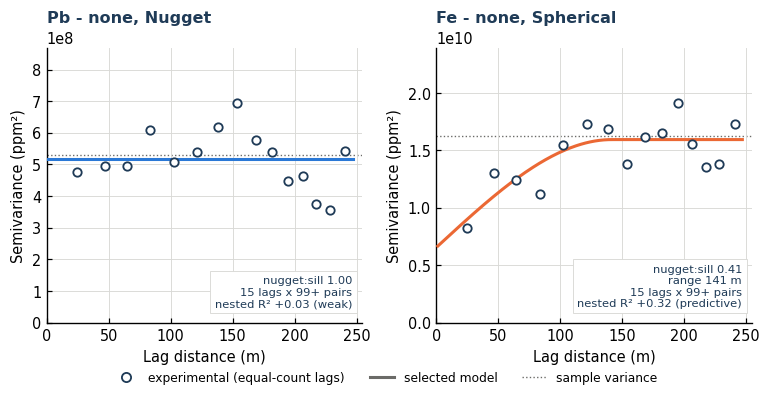

In [89]:
# Figure 3 - experimental variogram and selected model, one panel per element
fig, axes = plt.subplots(1, len(RES_ELS), figsize=(3.55 * len(RES_ELS), 3.5), squeeze=False)
for ax, el in zip(axes[0], RES_ELS):
    f = FITS[el]
    vg, m = f["vgm"], f["model"]
    h = np.linspace(0, f["cutoff"], 200)
    ax.axhline(f["sample_variance"], color=C_MUTED, lw=0.9, ls=":", zorder=1)
    ax.plot(h[1:], m.gamma(h[1:]), color=ELEMENT_COLOUR[el], lw=2.0, zorder=3)
    ax.scatter(vg["h_mean"], vg["gamma"], s=30, facecolor="white", edgecolor=C_INK, linewidths=1.2, zorder=4)
    ax.set_xlim(0, f["cutoff"] * 1.03); ax.set_ylim(0, max(vg["gamma"].max(), f["sample_variance"]) * 1.25)
    ax.grid(color=C_GRID, lw=0.6)
    ax.set_xlabel("Lag distance (m)")
    ax.set_ylabel("Semivariance" + {"none": " (ppm²)", "log": " (ln ppm)²", "nscore": " (normal scores)"}[f["transform"]])
    ax.set_title(f"{el} - {f['transform']}, {m.name}", loc="left", fontweight="bold", color=C_INK)
    txt = (f"nugget:sill {m.nugget / m.sill:.2f}" + ("" if m.name == "Nugget" else f"\nrange {m.rng:.0f} m")
           + f"\n{len(vg)} lags x {int(vg['n_pairs'].min())}+ pairs\nnested R² {f['r2_nested']:+.2f} ({f['reliability']})")
    ax.text(0.97, 0.05, txt, transform=ax.transAxes, ha="right", va="bottom", fontsize=7.5, color=C_INK,
            bbox=dict(fc="white", ec=C_GRID, lw=0.6, pad=3))
fig.legend(handles=[Line2D([0], [0], marker="o", color="w", mfc="white", mec=C_INK, mew=1.2, label="experimental (equal-count lags)"),
                    Line2D([0], [0], color=C_MUTED, lw=2, label="selected model"),
                    Line2D([0], [0], color=C_MUTED, lw=0.9, ls=":", label="sample variance")],
           loc="lower center", ncol=3, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout()
savefig(fig, "Fig3_variograms_shortlisted_CRMs")
plt.show()

## 9 · Stage D Kriging the Blocks

Each shortlisted element is kriged once at the block centres with its selected transform and model, and
back-transformed to ppm. A block centre farther from any station than the largest nearest-neighbour distance
between stations is flagged as extrapolated.

In [90]:
def krige_blocks(coords, f):
    """Ordinary kriging at every block centre with the selection `f`; returns (grade ppm, SD ppm, n negative clipped)."""
    r = ok_batch(BLK_XY, coords, f["y"], f["model"], radius=f["radius"])
    Z = r["est"] if f["transform"] == "none" else f["tf"].back(r["est"], var=r["var"], mu=r["mu"])
    n_neg = int(np.sum(Z < 0))
    Z = np.clip(Z, 0.0, None)
    return Z, f["tf"].back_sd(r["est"], r["var"], Z), n_neg, r

BLK_GRADE, BLK_SD, BLK_EXTRAP = {}, {}, {}
for el in RES_ELS:
    S, f = STATIONS[el], FITS[el]
    Z, SD, n_neg, r = krige_blocks(S["coords"], f)
    BLK_GRADE[el], BLK_SD[el] = Z, SD
    BLK_EXTRAP[el] = cKDTree(S["coords"]).query(BLK_XY, k=1)[0] > S["ex_d"]
    f["n_clipped"], f["cond_max"] = n_neg, r["cond_max"]
    f["var_ratio_blocks"] = float(np.var(Z) / np.var(S["v"], ddof=1))
    print(f"  {el:3s} blocks {Z.min():>8,.1f} - {Z.max():>8,.1f} ppm (stations {S['v'].min():,.1f} - {S['v'].max():,.1f}); "
          f"block variance = {100 * f['var_ratio_blocks']:.0f} % of the station variance (smoothing); "
          f"{100 * BLK_EXTRAP[el].mean():.0f} % of blocks extrapolated (> {S['ex_d']:.0f} m from a station)"
          + (f"; {n_neg} negative estimates clipped" if n_neg else ""))

  Pb  blocks 10,281.0 - 47,921.1 ppm (stations 312.5 - 106,790.4); block variance = 21 % of the station variance (smoothing); 0 % of blocks extrapolated (> 96 m from a station)
  Fe  blocks 14,680.3 - 347,504.1 ppm (stations 1,204.1 - 458,219.7); block variance = 41 % of the station variance (smoothing); 0 % of blocks extrapolated (> 96 m from a station)


## 10 · Stage E Mean Grade of the Waste and Its Uncertainty

In [91]:
def cov_structured(model, h):
    """Covariance of the structured part of a model (the nugget is added only on the station diagonal)."""
    h = np.asarray(h, float)
    if model.name == "Nugget":
        return np.zeros_like(h)
    return model.psill * (1.0 - SHAPES[model.name](h, model.rng))

_SUPER = (BLK_IY // 3) * (NCOL // 3 + 1) + (BLK_IX // 3)      # 9 m super-blocks, used only for the C(V,V) double sum
_, _SUPER_INV = np.unique(_SUPER, return_inverse=True)
_SUPER_INV = np.asarray(_SUPER_INV).ravel()

def global_ok_mean(coords, v, model, weights):
    """Ordinary kriging of the weighted mean of all blocks (unique neighbourhood, linear, grade units).
    Returns (estimate, standard error, kriging weights)."""
    n = len(v)
    wn = np.asarray(weights, float) / np.sum(weights)
    D = np.hypot(coords[:, None, 0] - coords[None, :, 0], coords[:, None, 1] - coords[None, :, 1])
    C = cov_structured(model, D) + model.nugget * np.eye(n)
    c_iV = np.array([np.sum(wn * cov_structured(model, np.hypot(BLK_XY[:, 0] - c[0], BLK_XY[:, 1] - c[1]))) for c in coords])
    ws = np.bincount(_SUPER_INV, weights=wn)
    keep = ws > 0
    cx = np.bincount(_SUPER_INV, weights=wn * BLK_XY[:, 0])[keep] / ws[keep]
    cy = np.bincount(_SUPER_INV, weights=wn * BLK_XY[:, 1])[keep] / ws[keep]
    ws = ws[keep]
    c_VV = 0.0
    for s in range(0, len(ws), 500):
        d = np.hypot(cx[s:s + 500, None] - cx[None, :], cy[s:s + 500, None] - cy[None, :])
        c_VV += float(np.sum(ws[s:s + 500, None] * ws[None, :] * cov_structured(model, d)))
    A = np.zeros((n + 1, n + 1)); A[:n, :n] = C; A[:n, n] = 1.0; A[n, :n] = 1.0
    sol = np.linalg.solve(A, np.append(c_iV, 1.0))
    lam, nu = sol[:n], sol[n]
    var = max(c_VV - lam @ c_iV - nu, 0.0)
    scale = max(1.0, float(np.var(v, ddof=1)) / model.sill)     # sill fitted inside the cut-off < variance of all pairs
    return float(lam @ v), float(np.sqrt(var * scale)), lam, scale

def polygonal_mean(coords, v, weights):
    i = cKDTree(coords).query(BLK_XY, k=1)[1]
    return float(np.sum(weights * v[i]) / np.sum(weights))

def grade_estimates(el, scen, coords=None, v=None, w=None, cands=None, f=None, Zblk=None):
    """All estimators of the mean grade (ppm) for one element under one base case."""
    S = STATIONS[el]
    coords = S["coords"] if coords is None else coords
    v = S["v"] if v is None else v
    w = S["w"] if w is None else w
    cands = CAND[el] if cands is None else cands
    f = FITS[el] if f is None else f
    Zblk = BLK_GRADE[el] if Zblk is None else Zblk
    vol = BLK_VOL[scen]
    raw_model = cands["none"]["model"]
    g_ok, se, lam, scale = global_ok_mean(coords, v, raw_model, vol)
    return dict(arithmetic=float(v.mean()), declustered=float(np.sum(w * v) / w.sum()),
                polygonal=polygonal_mean(coords, v, vol), block_model=float(np.sum(vol * Zblk) / vol.sum()),
                global_ok=g_ok, global_se=se, raw_model=raw_model.name, lam=lam, var_scale=scale,
                block_model_area=float(np.sum(BLK_AREA * Zblk) / BLK_AREA.sum()))

def adopted(est, basis):
    """Grade that enters the tonnage, and its range at CI_LEVEL (never narrower than the adopted value itself)."""
    g = est["block_model"] if basis == "block model" else est["global_ok"]
    lo = max(min(g, est["global_ok"] - Z_CI * est["global_se"]), 0.0)
    hi = max(g, est["global_ok"] + Z_CI * est["global_se"])
    return g, lo, hi

GRADE, rows = {}, []
for el in RES_ELS:
    GRADE[el] = {k: grade_estimates(el, k) for k in BLK_VOL}
    e = GRADE[el][BASE_CASE]
    g, lo, hi = adopted(e, FITS[el]["grade_basis"])
    e.update(adopted=g, lo=lo, hi=hi)
    others = [e["arithmetic"], e["declustered"], e["polygonal"], e["block_model"]]
    rows.append({"Element": el, "Arithmetic": e["arithmetic"], "Cell-declustered": e["declustered"],
                 "Polygonal": e["polygonal"], "Block model": e["block_model"], "Global OK": e["global_ok"],
                 "SE of global OK": e["global_se"], "Raw-space model": e["raw_model"], "Variance rescale": e["var_scale"],
                 "Relative SE %": 100 * e["global_se"] / e["global_ok"],
                 "Spread of the other four (% of global OK)": 100 * (max(others) - min(others)) / e["global_ok"],
                 "Estimators inside the range": f"{sum(lo <= x <= hi for x in others)} of 4",
                 "Basis": FITS[el]["grade_basis"], "Adopted (ppm)": g,
                 f"{100 * CI_LEVEL:.0f} % low": lo, f"{100 * CI_LEVEL:.0f} % high": hi})
GRADE_TABLE = pd.DataFrame(rows)
print(f"Thickness-weighted mean grade, base case on the {Z_BASE:g} m base (ppm):")
show_table(GRADE_TABLE, precision=1)
print(f"The range is the global-OK estimate +/- {Z_CI:.3f} standard errors (normal approximation; with {len(STATIONS[RES_ELS[0]]['v'])} "
      "skewed stations the true interval is asymmetric, wider upwards).")
print("Where 'Variance rescale' exceeds 1 the fitted sill was below the sample variance and the standard error was widened accordingly.")

Thickness-weighted mean grade, base case on the 193 m base (ppm):


Element,Arithmetic,Cell-declustered,Polygonal,Block model,Global OK,SE of global OK,Raw-space model,Variance rescale,Relative SE %,Spread of the other four (% of global OK),Estimators inside the range,Basis,Adopted (ppm),90 % low,90 % high
Pb,25416.9,22225.9,19585.1,22341.2,25416.9,2789.7,Nugget,1.0,11.0,22.9,3 of 4,global mean,25416.9,20828.3,30005.5
Fe,168111.8,154278.0,168756.9,170647.1,166429.4,17692.9,Spherical,1.0,10.6,9.8,4 of 4,block model,170647.1,137327.1,195531.7


The range is the global-OK estimate +/- 1.645 standard errors (normal approximation; with 68 skewed stations the true interval is asymmetric, wider upwards).
Where 'Variance rescale' exceeds 1 the fitted sill was below the sample variance and the standard error was widened accordingly.


## 11 · Stage E Tonnage, Grade and Contained Metal

In [92]:
def round_sig(x, n=ET_SIG_FIGS):
    if x is None or not np.isfinite(x) or x == 0:
        return x
    return float(round(x, int(n - 1 - np.floor(np.log10(abs(x))))))

RHO = BULK_DENSITY["base"]
V_A = float(BLK_VOL[BASE_CASE].sum())
TONNES = dict(low=BULK_DENSITY["low"] * (V_A - VOL_Q), base=RHO * V_A, high=BULK_DENSITY["high"] * (V_A + VOL_Q))

rows_base, rows_scen = [], []
RES = {}
for el in RES_ELS:
    basis = FITS[el]["grade_basis"]
    e = GRADE[el][BASE_CASE]
    M = {k: TONNES[k] * g * 1e-6 for k, g in (("low", e["lo"]), ("base", e["adopted"]), ("high", e["hi"]))}
    RES[el] = dict(grade=e["adopted"], g_lo=e["lo"], g_hi=e["hi"], metal=M["base"], m_lo=M["low"], m_hi=M["high"])
    rows_base.append({"Element": el, "Grade basis": basis,
                      "Tonnage low (Mt)": TONNES["low"] / 1e6, "Tonnage base (Mt)": TONNES["base"] / 1e6,
                      "Tonnage high (Mt)": TONNES["high"] / 1e6,
                      "Grade low (ppm)": e["lo"], "Grade base (ppm)": e["adopted"], "Grade high (ppm)": e["hi"],
                      "Metal low (t)": M["low"], "Metal base (t)": M["base"], "Metal high (t)": M["high"]})
    for k in BLK_VOL:
        g, lo, hi = adopted(GRADE[el][k], basis)
        T = RHO * BLK_VOL[k].sum()
        RES[el][f"metal_{k}"], RES[el][f"grade_{k}"] = T * g * 1e-6, g
        rows_scen.append({"Element": el, "Thickness model": CASE_LABEL[k], "Volume (Mm3)": BLK_VOL[k].sum() / 1e6,
                          "Tonnage (Mt)": T / 1e6, "Grade (ppm)": g, "Contained metal (t)": T * g * 1e-6})
RESOURCE_BASE = pd.DataFrame(rows_base)
RESOURCE_SCEN = pd.DataFrame(rows_scen)

print(f"Base case: base at {Z_BASE:g} m a.s.l., homogeneous through the thickness, {V_A / 1e6:.3f} Mm3, bulk density {RHO:g} t/m3 -> {TONNES['base'] / 1e6:.2f} Mt "
      f"(range {TONNES['low'] / 1e6:.2f} - {TONNES['high'] / 1e6:.2f} Mt from density {BULK_DENSITY['low']:g} - {BULK_DENSITY['high']:g} t/m3 "
      f"and +/- {0.5 * DZ_STEP:g} m of DEM rounding)")
show_table(RESOURCE_BASE, precision=2)
print(f"\nBase case against the uniform slab (bulk density {RHO:g} t/m3, same grade basis):")
show_table(RESOURCE_SCEN, precision=2)
for el in RES_ELS:
    print(f"  {el}: uniform slab changes the contained metal by {100 * (RES[el]['metal_U'] / RES[el]['metal_A'] - 1):+.1f} % "
          f"({RES[el]['grade_A']:,.0f} -> {RES[el]['grade_U']:,.0f} ppm; tonnage unchanged)")

Base case: base at 193 m a.s.l., homogeneous through the thickness, 1.780 Mm3, bulk density 1.25 t/m3 -> 2.23 Mt (range 1.87 - 2.61 Mt from density 1.1 - 1.4 t/m3 and +/- 0.5 m of DEM rounding)


Element,Grade basis,Tonnage low (Mt),Tonnage base (Mt),Tonnage high (Mt),Grade low (ppm),Grade base (ppm),Grade high (ppm),Metal low (t),Metal base (t),Metal high (t)
Pb,global mean,1.87,2.23,2.61,20828.26,25416.87,30005.48,38923.77,56557.41,78193.15
Fe,block model,1.87,2.23,2.61,137327.12,170647.09,195531.65,256636.41,379722.53,509548.04



Base case against the uniform slab (bulk density 1.25 t/m3, same grade basis):


Element,Thickness model,Volume (Mm3),Tonnage (Mt),Grade (ppm),Contained metal (t)
Pb,DEM thickness on the 193 m base (base case),1.78,2.23,25416.87,56557.41
Pb,"uniform slab, 10.96 m everywhere",1.78,2.23,25416.87,56557.41
Fe,DEM thickness on the 193 m base (base case),1.78,2.23,170647.09,379722.53
Fe,"uniform slab, 10.96 m everywhere",1.78,2.23,171447.03,381502.53


  Pb: uniform slab changes the contained metal by +0.0 % (25,417 -> 25,417 ppm; tonnage unchanged)
  Fe: uniform slab changes the contained metal by +0.5 % (170,647 -> 171,447 ppm; tonnage unchanged)


### 11.1 · Sensitivity what moves the contained metal

One factor is changed at a time and the base-case contained metal is recomputed. The base elevation and the
vertical homogeneity are fixed by the base case and are therefore not among the factors; the uniform slab is
included because it is the other reading of the thickness assumption. Two of the tests refit the whole
kriging: one removes the station that lies outside the polygon, the other raises the assays that exceed the upper
reporting limit to `ODL_SENS_FACTOR` × that limit (their true value is unknown, only that it is higher).

Element,Factor,Metal low (t),Metal high (t),Low vs base %,High vs base %,Note
Pb,Bulk density,49770.5,63344.3,-12.0,12.0,
Pb,Mean grade (90 % range),46346.9,66768.0,-18.1,18.1,
Pb,DEM vertical rounding,53976.1,59138.7,-4.6,4.6,
Pb,Uniform slab (area-weighted grade),56557.4,56557.4,0.0,0.0,
Pb,Station outside polygon removed,56557.4,56798.1,0.0,0.4,none Nugget
Fe,Bulk density,334155.8,425289.2,-12.0,12.0,
Fe,Mean grade (90 % range),305579.2,435095.4,-19.5,14.6,
Fe,DEM vertical rounding,362391.6,397053.4,-4.6,4.6,
Fe,Uniform slab (area-weighted grade),379722.5,381502.5,0.0,0.5,
Fe,Station outside polygon removed,378804.3,379722.5,-0.2,0.0,none Spherical


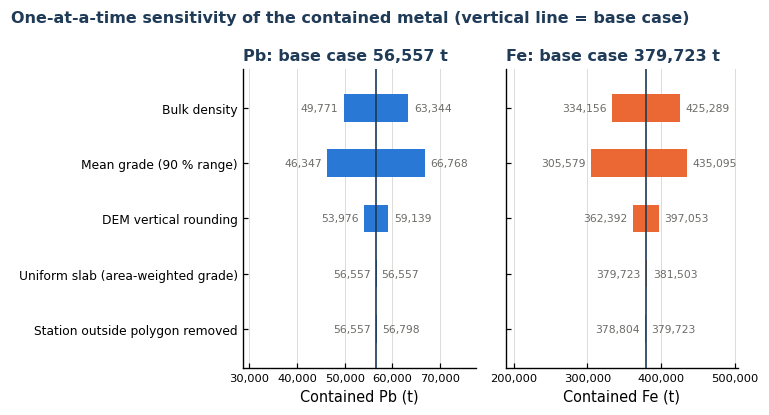

In [93]:
def refit_grade(el, keep=None, v_new=None):
    """Re-run declustering, Stage 2, block kriging and the grade estimators on a modified station set."""
    S = STATIONS[el]
    coords, v = S["coords"], (S["v"] if v_new is None else v_new)
    if keep is not None:
        coords, v = coords[keep], v[keep]
    w, _, _ = declustering_weights(coords, v)
    cands, f = fit_element(coords, v, w, label=el)
    Z, _, _, _ = krige_blocks(coords, f)
    e = grade_estimates(el, BASE_CASE, coords=coords, v=v, w=w, cands=cands, f=f, Zblk=Z)
    return adopted(e, FITS[el]["grade_basis"])[0], f      # same basis as the base case, to isolate the effect

SENS, rows = {}, []
for el in RES_ELS:
    S, R = STATIONS[el], RES[el]
    M0 = R["metal"]
    items = [("Bulk density", M0 * BULK_DENSITY["low"] / RHO, M0 * BULK_DENSITY["high"] / RHO, ""),
             (f"Mean grade ({100 * CI_LEVEL:.0f} % range)", TONNES["base"] * R["g_lo"] * 1e-6, TONNES["base"] * R["g_hi"] * 1e-6, ""),
             ("DEM vertical rounding", M0 * (V_A - VOL_Q) / V_A, M0 * (V_A + VOL_Q) / V_A, ""),
             ("Uniform slab (area-weighted grade)", min(R["metal_U"], M0), max(R["metal_U"], M0), "")]
    if (~S["inside"]).any():
        g2, f2 = refit_grade(el, keep=S["inside"])
        m2 = TONNES["base"] * g2 * 1e-6
        items.append(("Station outside polygon removed", min(m2, M0), max(m2, M0), f"{f2['transform']} {f2['model'].name}"))
        R["metal_no_outside"] = m2
    if S["odl"].any():
        g3, f3 = refit_grade(el, v_new=np.where(S["odl"], S["v"] * ODL_SENS_FACTOR / ODL_FACTOR, S["v"]))
        m3 = TONNES["base"] * g3 * 1e-6
        items.append((f"Over-range assays at {ODL_SENS_FACTOR:g} x limit", min(m3, M0), max(m3, M0), f"{f3['transform']} {f3['model'].name}"))
        R["metal_odl"] = m3
    SENS[el] = items
    for name, lo, hi, note in items:
        rows.append({"Element": el, "Factor": name, "Metal low (t)": lo, "Metal high (t)": hi,
                     "Low vs base %": 100 * (lo / M0 - 1), "High vs base %": 100 * (hi / M0 - 1), "Note": note})
SENS_TABLE = pd.DataFrame(rows)
show_table(SENS_TABLE, precision=1)

# Figure 4 - one panel per element, one measure (contained metal), bars span low to high around the base case
_factors = list(dict.fromkeys(n for el in RES_ELS for n, *_ in SENS[el]))[::-1]
fig, axes = plt.subplots(1, len(RES_ELS), figsize=(3.5 * len(RES_ELS), 0.42 * len(_factors) + 1.7), sharey=True, squeeze=False)
for ax, el in zip(axes[0], RES_ELS):
    M0 = RES[el]["metal"]
    for name, lo, hi, note in SENS[el]:
        yk = _factors.index(name)
        ax.barh(yk, max(hi - lo, M0 * 0.004), left=lo, height=0.5, color=ELEMENT_COLOUR[el], zorder=3)
        ax.text(lo - 0.02 * M0, yk, f"{lo:,.0f}", ha="right", va="center", fontsize=7, color=C_MUTED)
        ax.text(hi + 0.02 * M0, yk, f"{hi:,.0f}", ha="left", va="center", fontsize=7, color=C_MUTED)
    ax.axvline(M0, color=C_INK, lw=1.1, zorder=4)
    ax.set_xlim(min(l for _, l, _, _ in SENS[el]) * 0.62, max(h for _, _, h, _ in SENS[el]) * 1.16)
    ax.set_yticks(range(len(_factors))); ax.set_yticklabels(_factors, fontsize=8)
    ax.set_ylim(-0.7, len(_factors) - 0.3)
    ax.grid(axis="x", color=C_GRID, lw=0.6, zorder=0)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.tick_params(axis="x", labelsize=7.5)
    ax.set_xlabel(f"Contained {el} (t)")
    ax.set_title(f"{el}: base case {M0:,.0f} t", loc="left", fontweight="bold", color=C_INK)
fig.suptitle("One-at-a-time sensitivity of the contained metal (vertical line = base case)", x=0.01, ha="left",
             fontsize=10.5, fontweight="bold", color=C_INK)
plt.tight_layout()
savefig(fig, "Fig4_sensitivity_contained_metal")
plt.show()

## 12 · Grade Maps, Metal Accumulation and Grade–Tonnage Curves

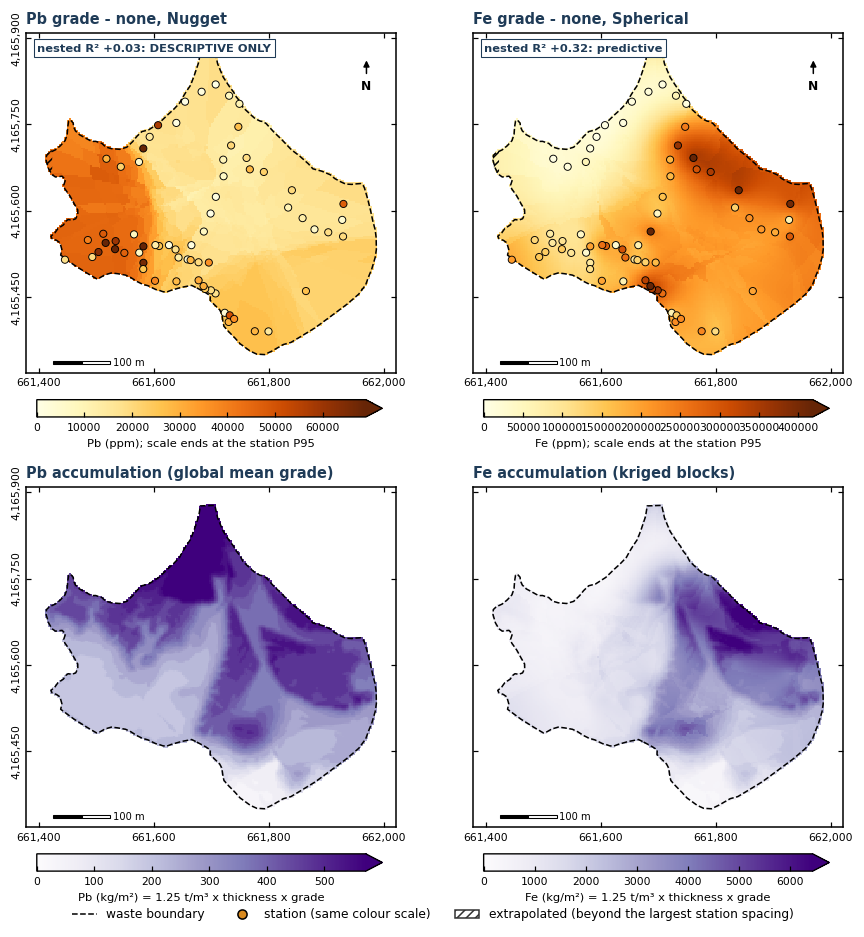

In [94]:
fig, axes = plt.subplots(2, len(RES_ELS), figsize=(4.15 * len(RES_ELS), 8.4), squeeze=False)
for j, el in enumerate(RES_ELS):
    S, f = STATIONS[el], FITS[el]
    Z = BLK_GRADE[el]
    vmax = float(np.percentile(S["v"], 95))
    ax = axes[0, j]
    im = ax.imshow(to_grid(Z), extent=EXTENT, origin="lower", cmap="YlOrBr", vmin=0, vmax=vmax, interpolation="nearest", zorder=1)
    ax.contourf(XG, YG, np.nan_to_num(to_grid(BLK_EXTRAP[el].astype(float)), nan=0.0), levels=[0.5, 1.5], colors="none",
                hatches=["////"], zorder=2)
    ax.scatter(S["coords"][:, 0], S["coords"][:, 1], c=S["v"], cmap="YlOrBr", vmin=0, vmax=vmax, s=22,
               edgecolors="black", linewidths=0.6, zorder=10)
    map_frame(ax, f"{el} grade - {f['transform']}, {f['model'].name}", ylabels=(j == 0))
    cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.045, pad=0.07, extend="max")
    cb.set_label(f"{el} (ppm); scale ends at the station P95", fontsize=7.5); cb.ax.tick_params(labelsize=7)
    stamp = f"nested R² {f['r2_nested']:+.2f}: " + ("predictive" + (", marginal" if f["marginal"] else "")
                                                     if f["reliability"] == "predictive" else "DESCRIPTIVE ONLY")
    ax.text(0.03, 0.97, stamp, transform=ax.transAxes, fontsize=7.5, va="top", ha="left", zorder=12, color=C_INK,
            fontweight="bold", bbox=dict(fc="white", ec=C_INK, lw=0.7, pad=2.5))
    Zacc = Z if f["grade_basis"] == "block model" else np.full_like(Z, RES[el]["grade"])
    acc = RHO * BLK_TH[BASE_CASE] * Zacc * 1e-3                   # kg of metal per m2
    ax = axes[1, j]
    im = ax.imshow(to_grid(acc), extent=EXTENT, origin="lower", cmap="Purples", vmin=0, vmax=float(np.percentile(acc, 99)),
                   interpolation="nearest", zorder=1)
    map_frame(ax, f"{el} accumulation ({'kriged blocks' if f['grade_basis'] == 'block model' else 'global mean grade'})",
              ylabels=(j == 0), north=False)
    cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.045, pad=0.07, extend="max")
    cb.set_label(f"{el} (kg/m²) = {RHO:g} t/m³ x thickness x grade", fontsize=7.5); cb.ax.tick_params(labelsize=7)
fig.legend(handles=[Line2D([0], [0], color="black", lw=1.0, ls="--", label="waste boundary"),
                    Line2D([0], [0], marker="o", color="w", mfc="#d98a1f", mec="black", ms=6, label="station (same colour scale)"),
                    Patch(fc="white", ec="0.2", hatch="////", label="extrapolated (beyond the largest station spacing)")],
           loc="lower center", ncol=3, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.015))
plt.tight_layout()
savefig(fig, "Fig5_grade_and_accumulation_maps")
plt.show()

### 12.1 · Grade - tonnage curves

Curves are drawn only for elements whose surface has cross-validated predictive skill. Even for those, kriging
smooths: the blocks vary far less than the samples (Section 9 gives the ratio), so a curve read from kriged blocks
**understates the tonnage above a high cut-off and overstates it above a low one**. The curves show how the
inventory is distributed in the model; they are not a statement of what selective recovery would achieve.

Element,Cut-off,Cut-off (ppm),Tonnage (Mt),% of tonnage,Grade above cut-off (ppm),Contained metal (t)
Fe,no cut-off,0.00,2.23,100.00,170647.09,379722.53
Fe,station P25,63999.03,1.77,79.67,203914.14,361498.22
Fe,station P50,144935.38,1.41,63.15,231120.38,324761.41
Fe,station P75,251081.33,0.40,17.81,295260.37,117002.83


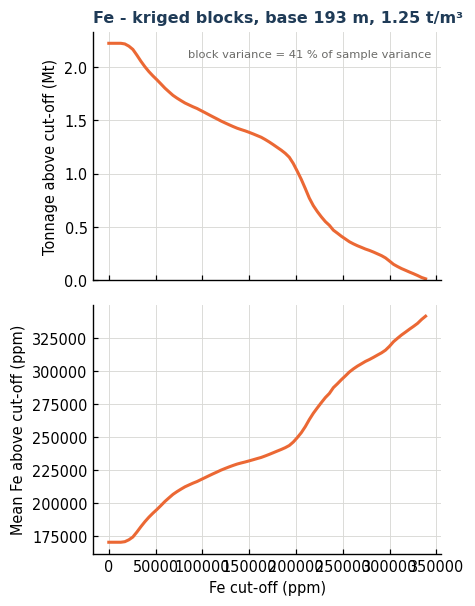

No grade-tonnage curve for Pb: the surface has no cross-validated predictive skill, so a curve would only describe the smoothing. These elements are carried at their global mean grade.


In [95]:
GT_ELS = [el for el in RES_ELS if FITS[el]["grade_basis"] == "block model"]
GT, rows = {}, []
vol = BLK_VOL[BASE_CASE]
for el in GT_ELS:
    Z, S = BLK_GRADE[el], STATIONS[el]
    cuts = np.linspace(0.0, float(np.percentile(Z, 99.5)), 80)
    T = np.array([RHO * vol[Z >= c].sum() for c in cuts])
    Gm = np.array([np.sum(vol[Z >= c] * Z[Z >= c]) / max(vol[Z >= c].sum(), 1e-12) for c in cuts])
    GT[el] = dict(cuts=cuts, T=T, G=Gm)
    marks = [("no cut-off", 0.0)] + [(f"station P{p}", float(np.percentile(S["v"], p))) for p in (25, 50, 75)]
    if CUTOFF_PPM.get(el):
        marks.append(("break-even cut-off", float(CUTOFF_PPM[el])))
    for name, c in marks:
        sel = Z >= c
        t = RHO * vol[sel].sum()
        g = np.sum(vol[sel] * Z[sel]) / vol[sel].sum() if sel.any() else np.nan
        rows.append({"Element": el, "Cut-off": name, "Cut-off (ppm)": c, "Tonnage (Mt)": t / 1e6,
                     "% of tonnage": 100 * t / (RHO * vol.sum()), "Grade above cut-off (ppm)": g,
                     "Contained metal (t)": t * g * 1e-6 if sel.any() else 0.0})
GT_TABLE = pd.DataFrame(rows)
if GT_ELS:
    show_table(GT_TABLE, precision=2)
    fig, axes = plt.subplots(2, len(GT_ELS), figsize=(4.4 * len(GT_ELS), 5.6), sharex="col", squeeze=False)
    for j, el in enumerate(GT_ELS):
        g = GT[el]
        axes[0, j].plot(g["cuts"], g["T"] / 1e6, color=ELEMENT_COLOUR[el], lw=2)
        axes[1, j].plot(g["cuts"], g["G"], color=ELEMENT_COLOUR[el], lw=2)
        axes[0, j].set_ylabel("Tonnage above cut-off (Mt)"); axes[1, j].set_ylabel(f"Mean {el} above cut-off (ppm)")
        axes[1, j].set_xlabel(f"{el} cut-off (ppm)")
        axes[0, j].set_title(f"{el} - kriged blocks, base {Z_BASE:g} m, {RHO:g} t/m³", loc="left", fontweight="bold", color=C_INK)
        axes[0, j].set_ylim(0, None)
        for a in axes[:, j]:
            a.grid(color=C_GRID, lw=0.6)
        axes[0, j].text(0.97, 0.93, f"block variance = {100 * FITS[el]['var_ratio_blocks']:.0f} % of sample variance",
                        transform=axes[0, j].transAxes, ha="right", va="top", fontsize=7.5, color=C_MUTED)
    plt.tight_layout()
    savefig(fig, "Fig6_grade_tonnage_curves")
    plt.show()
_no = [el for el in RES_ELS if el not in GT_ELS]
if _no:
    print("No grade-tonnage curve for " + ", ".join(_no) + ": the surface has no cross-validated predictive skill, so a "
          "curve would only describe the smoothing. These elements are carried at their global mean grade.")